# Meqsed

### meqsed odurki bizde studyinstanceid var ve onlarin ozlerine aid feature var. Biz sample submission fayli ucun herbir studyinstanceid ucun 12 dene feature cixarmaliyiq ve vermeliyik. Yalniz test faylinin icinde knee MRI sekilleri var

### .dcm - MRI sekli; train.csv - hansi xesteliklerin oldugu, hansi studylerin icinde hansi MRI seriesler var ve bu ne tip goruntudur

In [1]:
"""import os

csv_files = []

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.lower().endswith('.csv'):
            csv_files.append(os.path.join(dirname, filename))

for file in csv_files:
    print(file)"""

"import os\n\ncsv_files = []\n\nfor dirname, _, filenames in os.walk('/kaggle/input'):\n    for filename in filenames:\n        if filename.lower().endswith('.csv'):\n            csv_files.append(os.path.join(dirname, filename))\n\nfor file in csv_files:\n    print(file)"

In [2]:
import os

path = "/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series"
sumitems = 0 

for item in os.listdir(path):
    sumitems += 1
print(sumitems)

4407


In [3]:
import kagglehub

# Download latest version
path = kagglehub.model_download("qwen-lm/qwen2.5/transformers/7b")

print("Path to model files:", path)

Path to model files: /kaggle/input/models/qwen-lm/qwen2.5/transformers/7b/1


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
import seaborn as sns
from transformers import TrainingArguments, Trainer

# Data analysis

In [5]:
new_train_file = pd.read_csv("/kaggle/input/datasets/thesharifzade/newtrainfile/new_train_checkpoint.csv")

In [6]:
train_series = pd.read_csv("/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series.csv")

In [7]:
train_series.head()

,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.12343110195036213483...,1,1,Sagittal
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.13821229744997220641...,1,1,Axial
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.23084836536722595275...,0,0,Coronal
3,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.40734206102458723096...,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.75714899997203615784...,0,0,Sagittal


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
import seaborn as sns
from transformers import TrainingArguments, Trainer

In [9]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [10]:
!pip install --no-index "/kaggle/input/datasets/thesharifzade/torchao/torchao_pkg/torchao-0.16.0-cp310-abi3-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl"

Processing /kaggle/input/datasets/thesharifzade/torchao/torchao_pkg/torchao-0.16.0-cp310-abi3-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl


# Training Dataset

In [11]:
train_dataset = pd.read_csv("/kaggle/input/competitions/rsna-knee-abnormality-detection/train.csv")

In [12]:
train_dataset.head()

,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,Técnica: RMN de la rodilla. Resultados: Rotura...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,[DATE]: * MR Knie Rechts 15ch AA Klinische Inl...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,Hallazgos:\nNo hay alteraciones en significati...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,"In the medial compartment, the meniscus is no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,CONSTATATIONS :\n\nFractures :\nAucune.\n\nAli...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
train_dataset.nunique()

StudyInstanceUID    4407
Report              4276
ACL                    2
MCL                    2
Medial Meniscus        2
Lateral Meniscus       2
Medial OA              2
Lateral OA             2
PF OA                  2
Effusion               2
Synovitis              2
Baker's                2
Contusion              2
Fracture               2
dtype: int64

In [14]:
train_dataset.shape

(4407, 14)

In [15]:
train_dataset.dtypes

StudyInstanceUID     object
Report               object
ACL                 float64
MCL                 float64
Medial Meniscus     float64
Lateral Meniscus    float64
Medial OA           float64
Lateral OA          float64
PF OA               float64
Effusion            float64
Synovitis           float64
Baker's             float64
Contusion           float64
Fracture            float64
dtype: object

In [16]:
train_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4407 entries, 0 to 4406
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   StudyInstanceUID  4407 non-null   object 
 1   Report            4407 non-null   object 
 2   ACL               58 non-null     float64
 3   MCL               58 non-null     float64
 4   Medial Meniscus   58 non-null     float64
 5   Lateral Meniscus  58 non-null     float64
 6   Medial OA         58 non-null     float64
 7   Lateral OA        58 non-null     float64
 8   PF OA             58 non-null     float64
 9   Effusion          58 non-null     float64
 10  Synovitis         58 non-null     float64
 11  Baker's           58 non-null     float64
 12  Contusion         58 non-null     float64
 13  Fracture          58 non-null     float64
dtypes: float64(12), object(2)
memory usage: 482.1+ KB


In [17]:
train_dataset.isnull().sum()

StudyInstanceUID       0
Report                 0
ACL                 4349
MCL                 4349
Medial Meniscus     4349
Lateral Meniscus    4349
Medial OA           4349
Lateral OA          4349
PF OA               4349
Effusion            4349
Synovitis           4349
Baker's             4349
Contusion           4349
Fracture            4349
dtype: int64

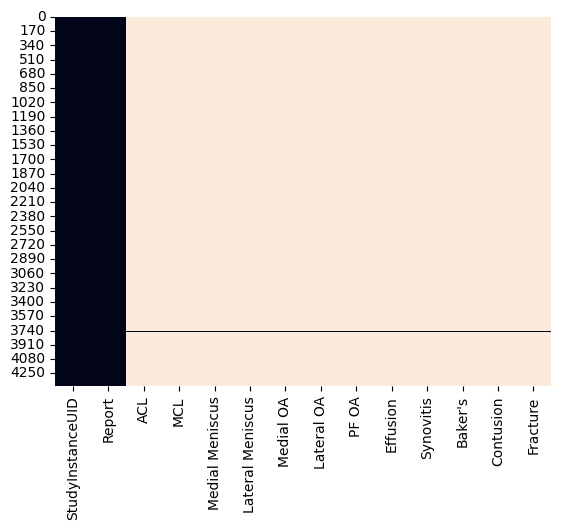

In [18]:
sns.heatmap(train_dataset.isnull(), cbar=False)
plt.show()

In [19]:
train_dataset.describe()

,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
count,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000
mean,0.413793,0.155172,0.448276,0.396552,0.258621,0.189655,0.362069,0.603448,0.465517,0.206897,0.327586,0.310345
std,0.496814,0.365231,0.501661,0.493454,0.441701,0.395452,0.484796,0.493454,0.503166,0.408619,0.473432,0.466675
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,1.000000,1.000000,0.750000,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [20]:
train_dataset.describe(include='all')

,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
count,4407,4407,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000
unique,4407,4276,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,1.2.826.0.1.3680043.8.498.99957611207313098696...,Diz eklemi içi sıvı miktarı normal. Çapraz ve ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,0.413793,0.155172,0.448276,0.396552,0.258621,0.189655,0.362069,0.603448,0.465517,0.206897,0.327586,0.310345
std,NaN,NaN,0.496814,0.365231,0.501661,0.493454,0.441701,0.395452,0.484796,0.493454,0.503166,0.408619,0.473432,0.466675
min,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,NaN,NaN,1.000000,0.000000,1.000000,1.000000,0.750000,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000


In [21]:
train_dataset.corr(numeric_only = True)

,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
ACL,1.000000,0.123358,0.157774,-0.037015,-0.256382,-0.049267,-0.268756,0.251702,-0.082281,-0.083440,0.383232,0.268755
MCL,0.123358,1.000000,-0.194805,0.041959,-0.253125,-0.085866,-0.223790,-0.041959,-0.113571,-0.218895,0.106709,0.124226
Medial Meniscus,0.157774,-0.194805,1.000000,0.119748,0.417715,0.006099,0.042287,0.234607,0.201319,0.309876,-0.038208,0.069770
Lateral Meniscus,-0.037015,0.041959,0.119748,1.000000,0.406621,0.416974,0.122649,0.152795,0.162028,0.282027,-0.190331,-0.010508
Medial OA,-0.256382,-0.253125,0.417715,0.406621,1.000000,0.316903,0.374331,0.076328,0.238175,0.475958,-0.328350,-0.225982
Lateral OA,-0.049267,-0.085866,0.006099,0.416974,0.316903,1.000000,0.276110,0.212362,0.342038,0.404333,-0.243962,-0.134401
PF OA,-0.268756,-0.223790,0.042287,0.122649,0.374331,0.276110,1.000000,0.097360,0.303804,0.235148,-0.296526,-0.195198
Effusion,0.251702,-0.041959,0.234607,0.152795,0.076328,0.212362,0.097360,1.000000,0.403243,0.066006,0.115235,0.162876
Synovitis,-0.082281,-0.113571,0.201319,0.162028,0.238175,0.342038,0.303804,0.403243,1.000000,0.205966,0.085075,0.046374
Baker's,-0.083440,-0.218895,0.309876,0.282027,0.475958,0.404333,0.235148,0.066006,0.205966,1.000000,-0.084434,-0.158622


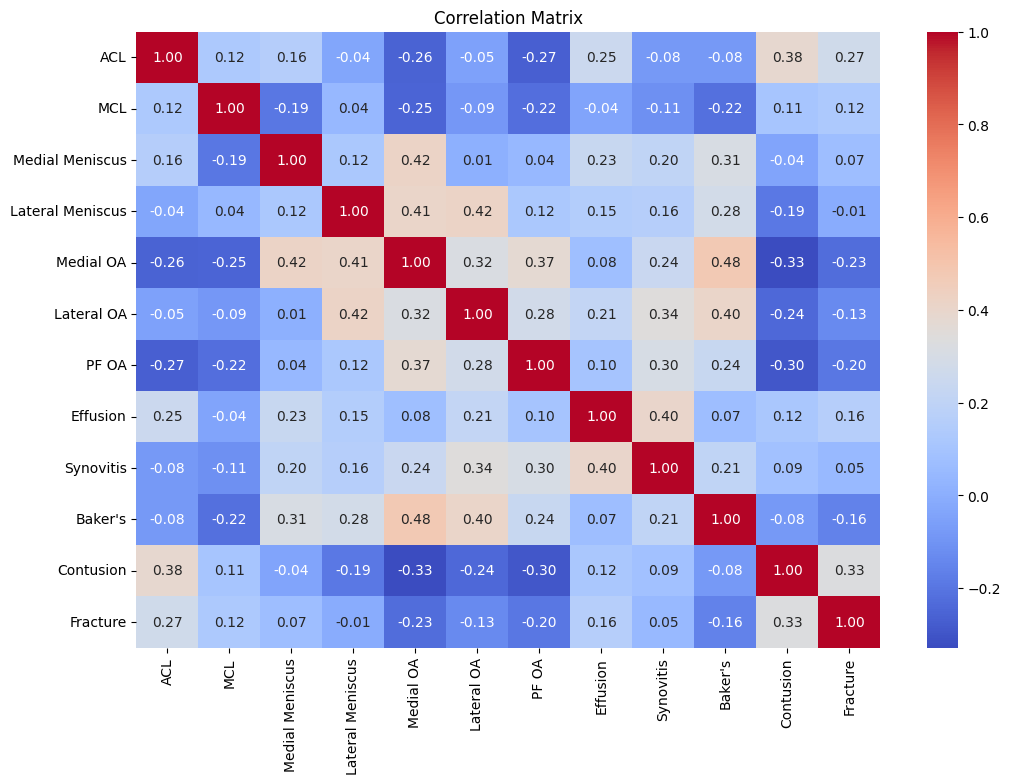

In [22]:
# Correlation matrix
corr = train_dataset.corr(numeric_only=True)

# Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix")
plt.show()

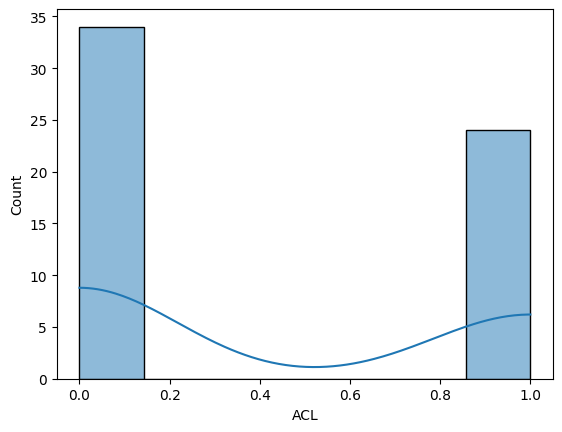

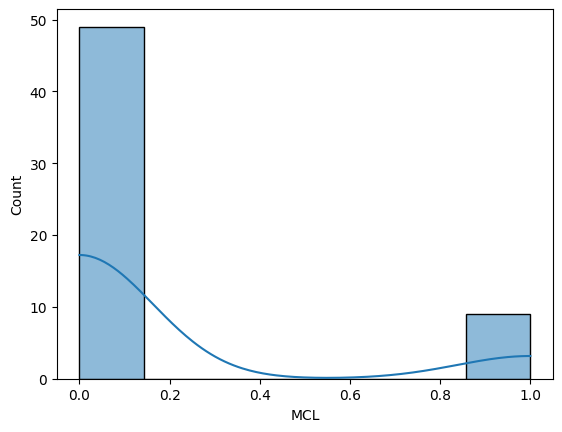

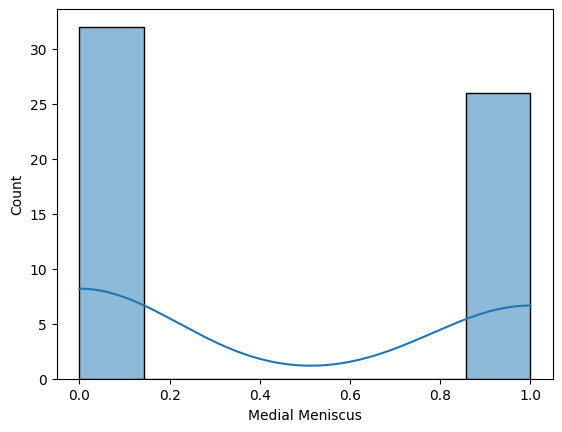

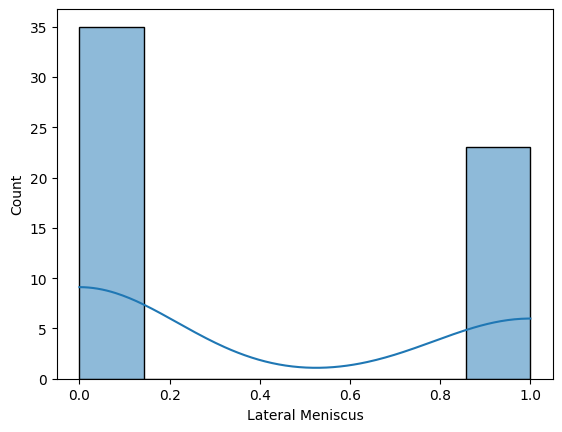

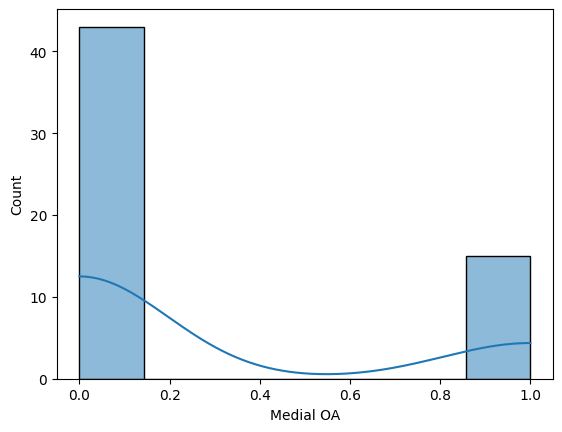

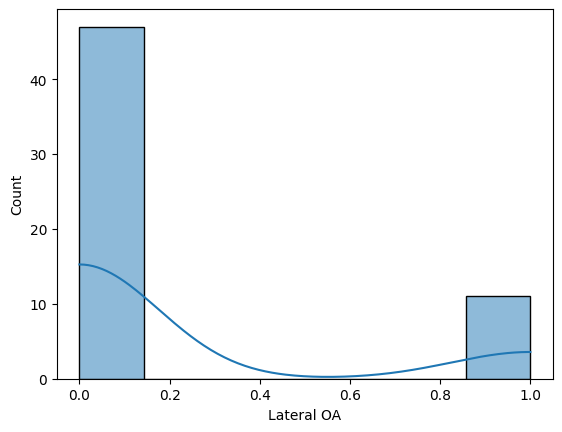

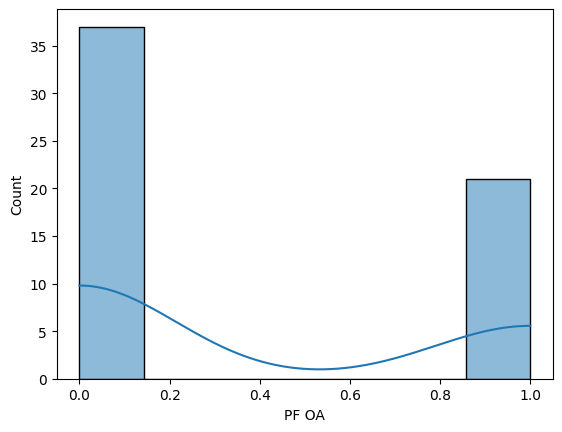

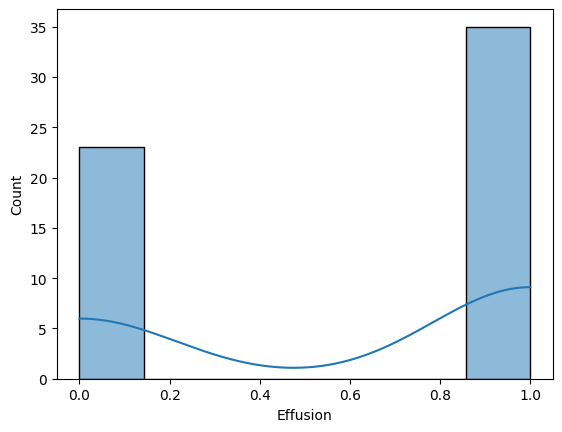

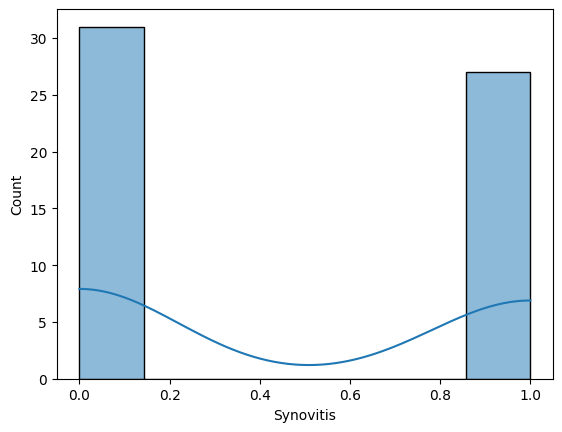

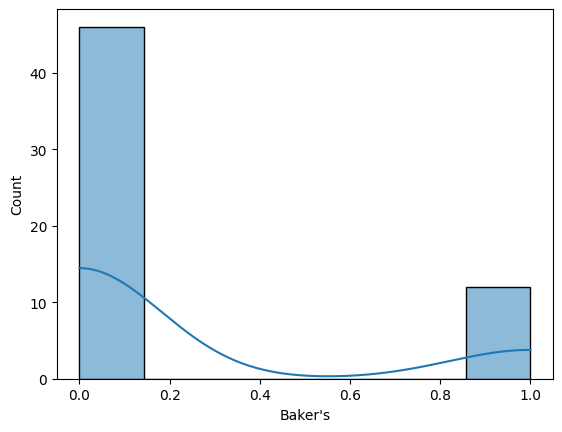

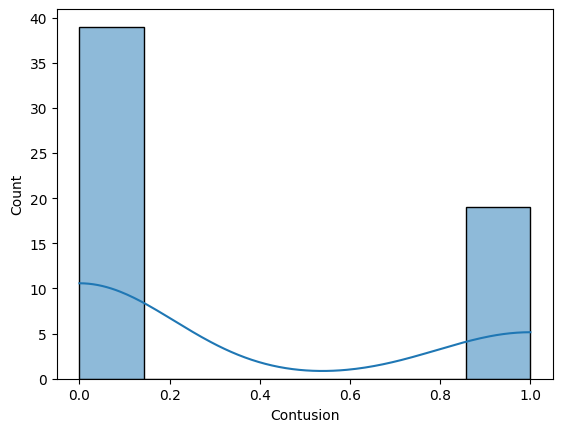

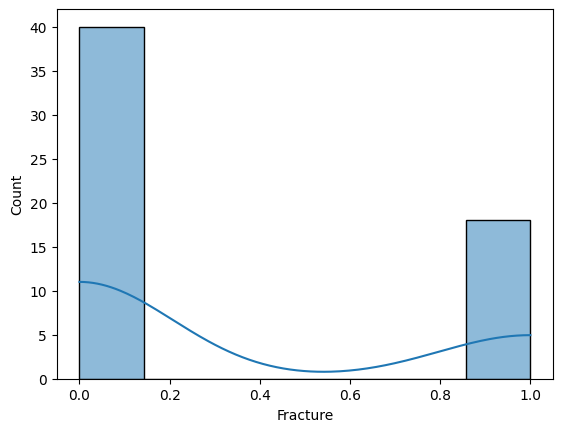

In [23]:
# Distribution 
numeric_cols = train_dataset.select_dtypes(include="number").columns
for i in numeric_cols:
    sns.histplot(train_dataset[i], kde=True)
    plt.show()

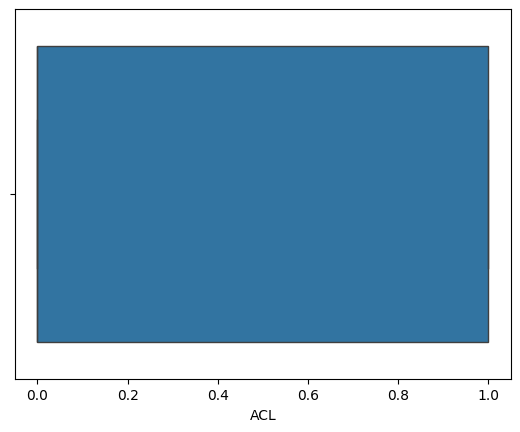

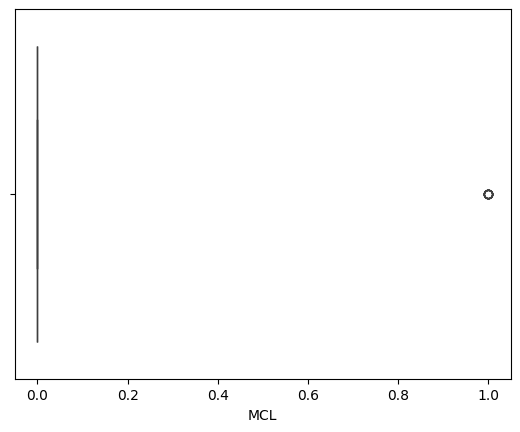

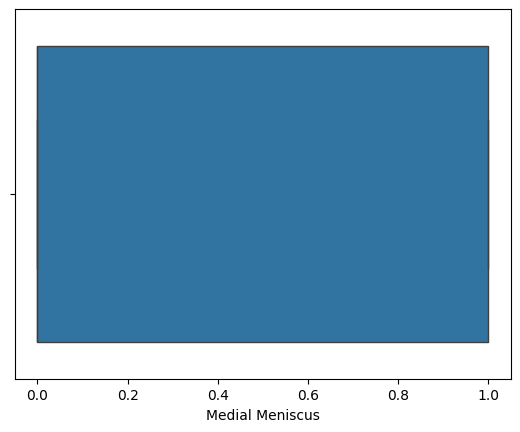

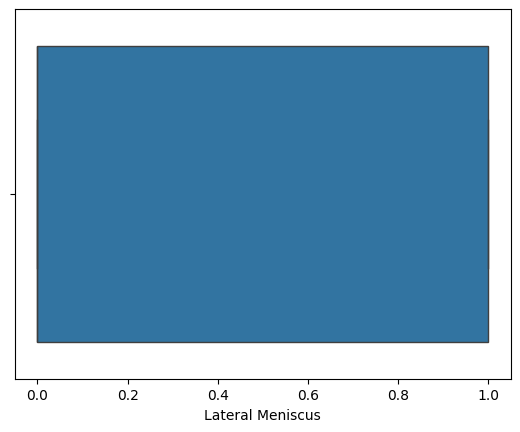

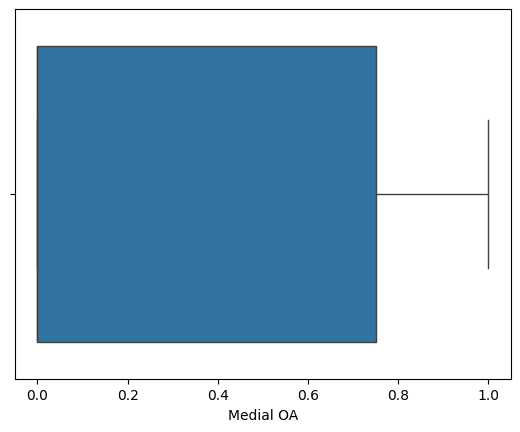

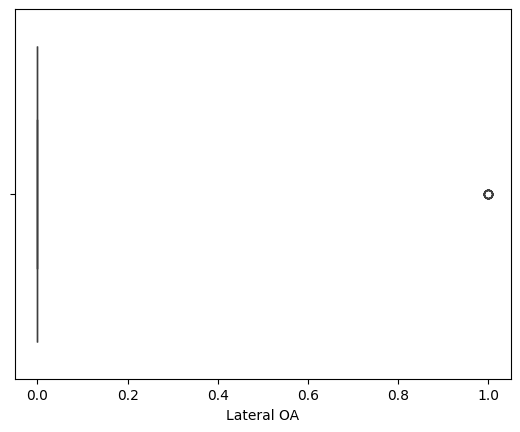

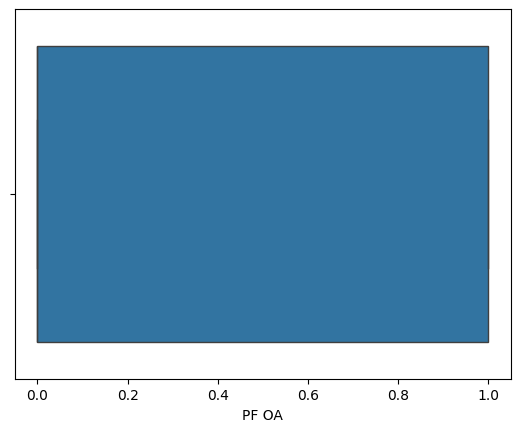

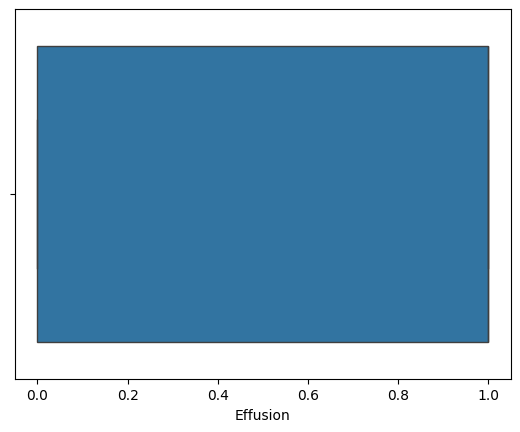

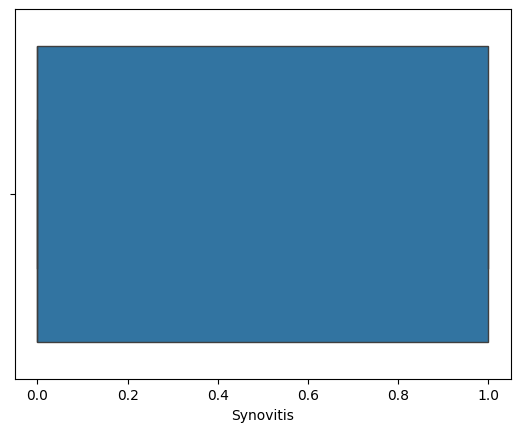

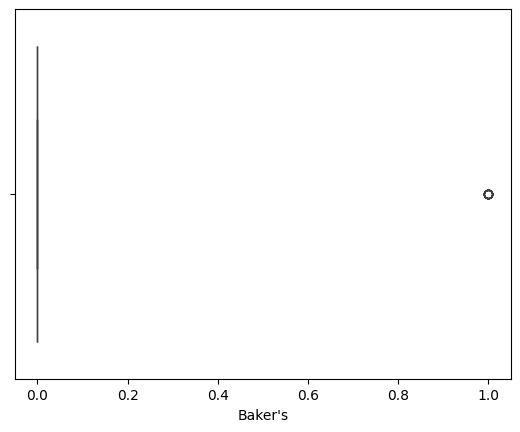

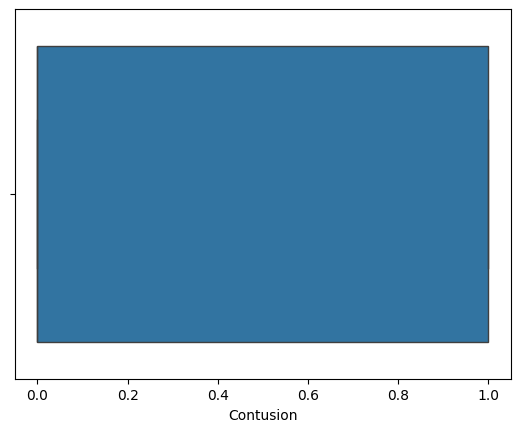

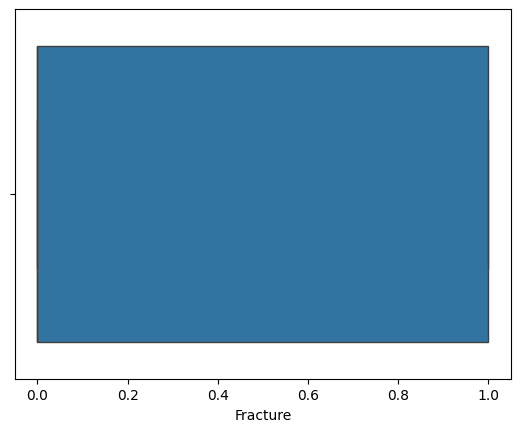

In [24]:
for i in numeric_cols:
    sns.boxplot(x=train_dataset[i])
    plt.show()

# Training dataset series

In [25]:
train_dataset_series = pd.read_csv("/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series.csv")

In [26]:
train_dataset_series.head()

,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.12343110195036213483...,1,1,Sagittal
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.13821229744997220641...,1,1,Axial
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.23084836536722595275...,0,0,Coronal
3,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.40734206102458723096...,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.75714899997203615784...,0,0,Sagittal


In [27]:
train_dataset_series.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24371 entries, 0 to 24370
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   StudyInstanceUID   24371 non-null  object
 1   SeriesInstanceUID  24371 non-null  object
 2   Fluid_Sensitive    24371 non-null  int64 
 3   Fat_Suppression    24371 non-null  int64 
 4   Anatomical_Plane   24371 non-null  object
dtypes: int64(2), object(3)
memory usage: 952.1+ KB


In [28]:
train_dataset_series.describe()

,Fluid_Sensitive,Fat_Suppression
count,24371.000000,24371.000000
mean,0.574864,0.574864
std,0.494374,0.494374
min,0.000000,0.000000
25%,0.000000,0.000000
50%,1.000000,1.000000
75%,1.000000,1.000000
max,1.000000,1.000000


In [29]:
train_dataset_series.describe(include ='all')

,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
count,24371,24371,24371.000000,24371.000000,24371
unique,4407,24371,NaN,NaN,3
top,1.2.826.0.1.3680043.8.498.63564058504808107209...,1.2.826.0.1.3680043.8.498.95722278506316542017...,NaN,NaN,Sagittal
freq,14,1,NaN,NaN,9864
mean,NaN,NaN,0.574864,0.574864,NaN
std,NaN,NaN,0.494374,0.494374,NaN
min,NaN,NaN,0.000000,0.000000,NaN
25%,NaN,NaN,0.000000,0.000000,NaN
50%,NaN,NaN,1.000000,1.000000,NaN
75%,NaN,NaN,1.000000,1.000000,NaN


In [30]:
train_dataset_series.shape

(24371, 5)

In [31]:
train_dataset_series.dtypes

StudyInstanceUID     object
SeriesInstanceUID    object
Fluid_Sensitive       int64
Fat_Suppression       int64
Anatomical_Plane     object
dtype: object

# Train series (images)

In [32]:
# burda demeli problem nedir seriesinstance uidler demeli studyinstance uidlerin icindedir
# ona gore birinci studyinstance id aldig sora seriesinstance id
import os

path = "/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series"

study = os.listdir(path)[0]

print("Study:", study)
print(os.listdir(os.path.join(path, study))[:20])

Study: 1.2.826.0.1.3680043.8.498.10843463954622076609489312662891432839
['1.2.826.0.1.3680043.8.498.28798546215369442215420222435134673142', '1.2.826.0.1.3680043.8.498.77574746339062590058612008891367008722', '1.2.826.0.1.3680043.8.498.11095855317733507937819924915747155492', '1.2.826.0.1.3680043.8.498.20777921698448069425369525866577598114', '1.2.826.0.1.3680043.8.498.12352363451108476518578557153043561806']


In [33]:
series = os.listdir(os.path.join(path, study))[0]

series_path = os.path.join(path, study, series)

print("Series:", series)
print(os.listdir(series_path)[:10])

Series: 1.2.826.0.1.3680043.8.498.28798546215369442215420222435134673142
['1.2.826.0.1.3680043.8.498.12486678153168904030743072482872142065.dcm', '1.2.826.0.1.3680043.8.498.86700687663805155070115680323395754377.dcm', '1.2.826.0.1.3680043.8.498.40362622123295797247686695535473040667.dcm', '1.2.826.0.1.3680043.8.498.22606964411658655718893941683908738828.dcm', '1.2.826.0.1.3680043.8.498.47226698003996911677858077867948563321.dcm', '1.2.826.0.1.3680043.8.498.41029266142968958477426135188058286555.dcm', '1.2.826.0.1.3680043.8.498.11454956388719760100970148944602145821.dcm', '1.2.826.0.1.3680043.8.498.10719509394839994049152771445326590008.dcm', '1.2.826.0.1.3680043.8.498.16426352596070175970567645162869213145.dcm', '1.2.826.0.1.3680043.8.498.37555643084024702418685746323961703329.dcm']


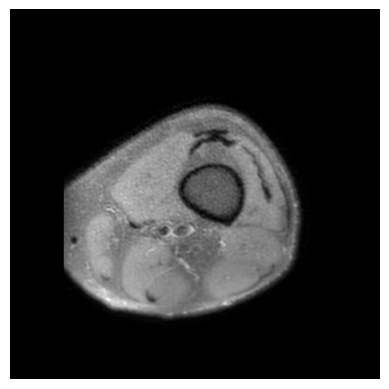

In [34]:
import os
import pydicom
import matplotlib.pyplot as plt

path = "/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series"

study = os.listdir(path)[0]
series = os.listdir(os.path.join(path, study))[0]

series_path = os.path.join(path, study, series)

dcm_file = [f for f in os.listdir(series_path) if f.endswith(".dcm")][0]

dcm = pydicom.dcmread(os.path.join(series_path, dcm_file))

plt.imshow(dcm.pixel_array, cmap="gray")
plt.axis("off")
plt.show()

# Training images with DinoV2

In [35]:
from transformers import AutoImageProcessor, AutoModel

model_path = "/kaggle/input/models/metaresearch/dinov2/pytorch/large/1"

# processor burda sekili dinoV2-nin basa duseceyi formata cevirir
# 512x512 -> RGB -> resize / normalize -> tensor
processor = AutoImageProcessor.from_pretrained(model_path)
model = AutoModel.from_pretrained(model_path).cuda()
model.eval()

The image processor of type `BitImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


Loading weights:   0%|          | 0/439 [00:00<?, ?it/s]

Dinov2Model(
  (embeddings): Dinov2Embeddings(
    (patch_embeddings): Dinov2PatchEmbeddings(
      (projection): Conv2d(3, 1024, kernel_size=(14, 14), stride=(14, 14))
    )
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (encoder): Dinov2Encoder(
    (layer): ModuleList(
      (0-23): 24 x Dinov2Layer(
        (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
        (attention): Dinov2Attention(
          (attention): Dinov2SelfAttention(
            (query): Linear(in_features=1024, out_features=1024, bias=True)
            (key): Linear(in_features=1024, out_features=1024, bias=True)
            (value): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (output): Dinov2SelfOutput(
            (dense): Linear(in_features=1024, out_features=1024, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
          )
        )
        (layer_scale1): Dinov2LayerScale()
        (drop_path): Identity()
        (norm2): LayerNorm((1024,),

In [36]:
import os
import pydicom
import numpy as np
from PIL import Image
import torch

path = "/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series"

# bir Study
study = os.listdir(path)[0]

# onun bir Series-i
series = os.listdir(os.path.join(path, study))[0]

series_path = os.path.join(path, study, series)

# bir DICOM
dcm_file = [f for f in os.listdir(series_path) if f.endswith(".dcm")][0]

dcm = pydicom.dcmread(os.path.join(series_path, dcm_file))

# DICOM -> image
img = dcm.pixel_array.astype(np.float32)

# normalize 0-255
img = (img - img.min()) / (img.max() - img.min()) * 255
img = img.astype(np.uint8)

# grayscale -> RGB
img = Image.fromarray(img).convert("RGB")

In [37]:
inputs = processor(
    images=img,
    return_tensors="pt"
).to("cuda")

print(inputs["pixel_values"].shape)

torch.Size([1, 3, 224, 224])


In [38]:
with torch.no_grad():
    outputs = model(**inputs)

print(outputs.last_hidden_state.shape)

torch.Size([1, 257, 1024])


In [39]:
feature = outputs.last_hidden_state[:, 0, :]

print(feature.shape)

torch.Size([1, 1024])


# Bidene experiment train_series ile train_series.csv arasindaki baglantini qurmaq ucun

In [40]:
"""
Demeli seriesler var ve onlarin icinde sekiller var
Biz indi birinci 1-ci seriesi goturub, icindeki sekilleri analiz edib, feature engineering edirik
ordaki fluit sensitive zad onlari labelleyeik ki 1024 dene yox cunki biz 1024x1024 elemisik
1027 yeni o ucunude bizim ucun versin dinoV2 yoxsa bele ozu bele dusune bilmir
Belke sonra experiment ucun 1024x1024 de qalib, ondan sonra qwen ile analiz edib basqa curde elemek olar

"""

'\nDemeli seriesler var ve onlarin icinde sekiller var\nBiz indi birinci 1-ci seriesi goturub, icindeki sekilleri analiz edib, feature engineering edirik\nordaki fluit sensitive zad onlari labelleyeik ki 1024 dene yox cunki biz 1024x1024 elemisik\n1027 yeni o ucunude bizim ucun versin dinoV2 yoxsa bele ozu bele dusune bilmir\nBelke sonra experiment ucun 1024x1024 de qalib, ondan sonra qwen ile analiz edib basqa curde elemek olar\n\n'

In [41]:
import pandas as pd
import os

df = pd.read_csv(
    "/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series.csv"
)

train_path = "/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series"

row = df.iloc[0]

study_id = row["StudyInstanceUID"]
series_id = row["SeriesInstanceUID"]

series_path = os.path.join(train_path, study_id, series_id)

print("Series:", series_id)
print("Folder exists:", os.path.exists(series_path))
print("DICOM count:", len([f for f in os.listdir(series_path) if f.endswith(".dcm")]))

Series: 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
Folder exists: True
DICOM count: 22


In [42]:
# burda ise biz processing edirik bir novu
features = []

dcm_files = sorted([
    f for f in os.listdir(series_path)
    if f.endswith(".dcm")
])

for file in dcm_files:
    dcm = pydicom.dcmread(os.path.join(series_path, file))

    img = dcm.pixel_array.astype(np.float32)
    img = (img - img.min()) / (img.max() - img.min()) * 255
    img = img.astype(np.uint8)

    img = Image.fromarray(img).convert("RGB")

    inputs = processor(images=img, return_tensors="pt").to("cuda")

    with torch.no_grad():
        output = model(**inputs)

    feature = output.last_hidden_state[:, 0, :]
    features.append(feature.cpu())

features = torch.cat(features, dim=0)

print(features.shape)

torch.Size([22, 1024])


In [43]:
series_feature = features.mean(dim=0)

print(series_feature.shape)

torch.Size([1024])


In [44]:
# Burda just bidene row-un fluit sensitive zad o melumatlarini bura yazir
row = df[df["SeriesInstanceUID"] == series_id].iloc[0]

fluid = row["Fluid_Sensitive"]
fat = row["Fat_Suppression"]
plane = row["Anatomical_Plane"]

print(fluid, fat, plane)

1 1 Sagittal


In [45]:
# Burda uje o 3 dene featurede elave olundu bizim ucun 
plane_map = {
    "Sagittal": 0,
    "Coronal": 1,
    "Axial": 2
}

plane_value = plane_map[plane]

metadata = torch.tensor([
    fluid,
    fat,
    plane_value
], dtype=torch.float32)

final_feature = torch.cat([
    series_feature,
    metadata
])

print(final_feature.shape)

torch.Size([1027])


In [46]:
# Nece dene series oldugunu gosterir bu
study_rows = df[df["StudyInstanceUID"] == study_id]

print(len(study_rows))
print(study_rows["SeriesInstanceUID"].tolist())

5
['1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772', '1.2.826.0.1.3680043.8.498.13821229744997220641575291927426543265', '1.2.826.0.1.3680043.8.498.23084836536722595275828690293168736174', '1.2.826.0.1.3680043.8.498.40734206102458723096154687147390476697', '1.2.826.0.1.3680043.8.498.75714899997203615784077798038670363546']


In [47]:
for series_id in study_rows["SeriesInstanceUID"]:
    row = df[df["SeriesInstanceUID"] == series_id].iloc[0]

    print(
        "| Series ID:",series_id,
        "| Fluid:", row["Fluid_Sensitive"],
        "| Fat:", row["Fat_Suppression"],
        "| Plane:", row["Anatomical_Plane"]
    )

| Series ID: 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772 | Fluid: 1 | Fat: 1 | Plane: Sagittal
| Series ID: 1.2.826.0.1.3680043.8.498.13821229744997220641575291927426543265 | Fluid: 1 | Fat: 1 | Plane: Axial
| Series ID: 1.2.826.0.1.3680043.8.498.23084836536722595275828690293168736174 | Fluid: 0 | Fat: 0 | Plane: Coronal
| Series ID: 1.2.826.0.1.3680043.8.498.40734206102458723096154687147390476697 | Fluid: 1 | Fat: 1 | Plane: Coronal
| Series ID: 1.2.826.0.1.3680043.8.498.75714899997203615784077798038670363546 | Fluid: 0 | Fat: 0 | Plane: Sagittal


In [48]:
series_features = {}

for series_id in study_rows["SeriesInstanceUID"]:

    series_path = os.path.join(
        train_path,
        study_id,
        series_id
    )

    features = []

    dcm_files = sorted([
        f for f in os.listdir(series_path)
        if f.endswith(".dcm")
    ])

    for file in dcm_files:
        dcm = pydicom.dcmread(
            os.path.join(series_path, file)
        )

        img = dcm.pixel_array.astype(np.float32)

        # normalize
        img = (img - img.min()) / (img.max() - img.min()) * 255
        img = img.astype(np.uint8)

        img = Image.fromarray(img).convert("RGB")

        inputs = processor(
            images=img,
            return_tensors="pt"
        ).to("cuda")

        with torch.no_grad():
            output = model(**inputs)

        feature = output.last_hidden_state[:, 0, :]
        features.append(feature.cpu())

    # DICOM-ları birləşdir
    features = torch.cat(features, dim=0)

    # Series feature
    series_feature = features.mean(dim=0)

    series_features[series_id] = series_feature

    print(series_id, "→", series_feature.shape)

1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772 → torch.Size([1024])
1.2.826.0.1.3680043.8.498.13821229744997220641575291927426543265 → torch.Size([1024])
1.2.826.0.1.3680043.8.498.23084836536722595275828690293168736174 → torch.Size([1024])
1.2.826.0.1.3680043.8.498.40734206102458723096154687147390476697 → torch.Size([1024])
1.2.826.0.1.3680043.8.498.75714899997203615784077798038670363546 → torch.Size([1024])


In [49]:
plane_map = {
    "Sagittal": 0,
    "Coronal": 1,
    "Axial": 2
}

final_series_features = {}

for series_id, feature in series_features.items():

    row = df[df["SeriesInstanceUID"] == series_id].iloc[0]

    metadata = torch.tensor([
        row["Fluid_Sensitive"],
        row["Fat_Suppression"],
        plane_map[row["Anatomical_Plane"]]
    ], dtype=torch.float32)

    final_feature = torch.cat([feature, metadata])

    final_series_features[series_id] = final_feature

    print(series_id, final_feature.shape)

1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772 torch.Size([1027])
1.2.826.0.1.3680043.8.498.13821229744997220641575291927426543265 torch.Size([1027])
1.2.826.0.1.3680043.8.498.23084836536722595275828690293168736174 torch.Size([1027])
1.2.826.0.1.3680043.8.498.40734206102458723096154687147390476697 torch.Size([1027])
1.2.826.0.1.3680043.8.498.75714899997203615784077798038670363546 torch.Size([1027])


In [50]:
study_feature = torch.stack(
    list(final_series_features.values())
).mean(dim=0)

print(study_feature.shape)

torch.Size([1027])


In [51]:
label_cols = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture"
]

train_df = train_dataset

train_labeled = train_df.dropna(subset=label_cols)

print(len(train_df))
print(len(train_labeled))

4407
58


In [52]:
print(train_labeled[label_cols].head())

     ACL  MCL  Medial Meniscus  Lateral Meniscus  Medial OA  Lateral OA  \
29   0.0  0.0              0.0               0.0        0.0         0.0   
63   0.0  0.0              0.0               1.0        0.0         0.0   
109  0.0  0.0              1.0               0.0        1.0         0.0   
445  0.0  0.0              0.0               0.0        0.0         0.0   
470  1.0  0.0              1.0               0.0        0.0         0.0   

     PF OA  Effusion  Synovitis  Baker's  Contusion  Fracture  
29     1.0       1.0        0.0      0.0        0.0       0.0  
63     1.0       0.0        1.0      0.0        0.0       0.0  
109    1.0       0.0        1.0      0.0        0.0       0.0  
445    0.0       1.0        0.0      0.0        0.0       0.0  
470    0.0       0.0        0.0      0.0        0.0       0.0  


In [53]:
label_cols = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture"
]

print("Total studies:", len(train_df))
print("Labeled studies:", train_df[label_cols].notna().all(axis=1).sum())

Total studies: 4407
Labeled studies: 58


In [54]:
labeled_studies = train_df[
    train_df[label_cols].notna().all(axis=1)
]

study_id = labeled_studies.iloc[0]["StudyInstanceUID"]

print("Study:", study_id)

Study: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149


In [55]:
study_series = df[
    df["StudyInstanceUID"] == study_id
]

print("Series count:", len(study_series))
print(study_series[
    ["SeriesInstanceUID", "Fluid_Sensitive",
     "Fat_Suppression", "Anatomical_Plane"]
])

Series count: 5
                                     SeriesInstanceUID  Fluid_Sensitive  \
163  1.2.826.0.1.3680043.8.498.10791858932231443712...                0   
164  1.2.826.0.1.3680043.8.498.12451507871565834868...                0   
165  1.2.826.0.1.3680043.8.498.21497837050858589852...                1   
166  1.2.826.0.1.3680043.8.498.37372672584387115708...                1   
167  1.2.826.0.1.3680043.8.498.67495435033389756963...                1   

     Fat_Suppression Anatomical_Plane  
163                0         Sagittal  
164                0          Coronal  
165                1          Coronal  
166                1         Sagittal  
167                1            Axial  


In [56]:
study_series_features = []

for _, row in study_series.iterrows():

    series_id = row["SeriesInstanceUID"]

    series_path = os.path.join(
        train_path,
        study_id,
        series_id
    )

    features = []

    dcm_files = sorted([
        f for f in os.listdir(series_path)
        if f.endswith(".dcm")
    ])

    for file in dcm_files:

        dcm = pydicom.dcmread(
            os.path.join(series_path, file)
        )

        img = dcm.pixel_array.astype(np.float32)

        img = (
            (img - img.min()) /
            (img.max() - img.min() + 1e-8)
            * 255
        ).astype(np.uint8)

        img = Image.fromarray(img).convert("RGB")

        inputs = processor(
            images=img,
            return_tensors="pt"
        ).to("cuda")

        with torch.no_grad():
            output = model(**inputs)

        feature = output.last_hidden_state[:, 0, :]
        features.append(feature.cpu())

    # DICOM-ları → Series feature
    features = torch.cat(features, dim=0)
    series_feature = features.mean(dim=0)

    study_series_features.append(series_feature)

    print(
        series_id,
        "DICOMs:", len(dcm_files),
        "Feature:", series_feature.shape
    )

1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282 DICOMs: 36 Feature: torch.Size([1024])
1.2.826.0.1.3680043.8.498.12451507871565834868863189854063726441 DICOMs: 30 Feature: torch.Size([1024])
1.2.826.0.1.3680043.8.498.21497837050858589852101556928971904198 DICOMs: 30 Feature: torch.Size([1024])
1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429 DICOMs: 36 Feature: torch.Size([1024])
1.2.826.0.1.3680043.8.498.67495435033389756963800730529101229430 DICOMs: 32 Feature: torch.Size([1024])


In [57]:
study_feature = torch.stack(
    study_series_features
).mean(dim=0)

print("Study feature:", study_feature.shape)

Study feature: torch.Size([1024])


In [58]:
labels = labeled_studies[
    labeled_studies["StudyInstanceUID"] == study_id
][label_cols].iloc[0].values.astype("float32")

labels = torch.tensor(labels)

print("Feature:", study_feature.shape)
print("Labels:", labels.shape)
print(labels)

Feature: torch.Size([1024])
Labels: torch.Size([12])
tensor([0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0.])


In [59]:
X = []
y = []

for _, study_row in labeled_studies.iterrows():

    study_id = study_row["StudyInstanceUID"]

    study_series = df[
        df["StudyInstanceUID"] == study_id
    ]

    series_features = []

    for _, series_row in study_series.iterrows():

        series_id = series_row["SeriesInstanceUID"]

        series_path = os.path.join(
            train_path,
            study_id,
            series_id
        )

        features = []

        dcm_files = sorted([
            f for f in os.listdir(series_path)
            if f.endswith(".dcm")
        ])

        for file in dcm_files:

            dcm = pydicom.dcmread(
                os.path.join(series_path, file)
            )

            img = dcm.pixel_array.astype(np.float32)

            img = (
                (img - img.min()) /
                (img.max() - img.min() + 1e-8)
                * 255
            ).astype(np.uint8)

            img = Image.fromarray(img).convert("RGB")

            inputs = processor(
                images=img,
                return_tensors="pt" # Pytorch tensor format
            ).to("cuda")

            with torch.no_grad():
                output = model(**inputs)

            feature = output.last_hidden_state[:, 0, :]
            features.append(feature.cpu())

        # DICOM → Series
        features = torch.cat(features, dim=0)
        series_feature = features.mean(dim=0)

        series_features.append(series_feature)

    # Series → Study
    study_feature = torch.stack(series_features).mean(dim=0)

    # Label
    labels = study_row[label_cols].values.astype("float32")

    X.append(study_feature)
    y.append(torch.tensor(labels))

    print("Done:", study_id)

Done: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Done: 1.2.826.0.1.3680043.8.498.10170898615867673028696505248839028269
Done: 1.2.826.0.1.3680043.8.498.10306159113324811538703788080836752052
Done: 1.2.826.0.1.3680043.8.498.11287937729196958426538087439102017580
Done: 1.2.826.0.1.3680043.8.498.11382021393803389951964005983002209238
Done: 1.2.826.0.1.3680043.8.498.11548045715264151632153040089882701935
Done: 1.2.826.0.1.3680043.8.498.11557620559191469069130827959098335840
Done: 1.2.826.0.1.3680043.8.498.11771393824519892797114773408583976756
Done: 1.2.826.0.1.3680043.8.498.11851412923016044948101698015974810604
Done: 1.2.826.0.1.3680043.8.498.11915937982684988073644209606907169581
Done: 1.2.826.0.1.3680043.8.498.12448079646359892252441208258836556945
Done: 1.2.826.0.1.3680043.8.498.12505035424093604269515328931488770819
Done: 1.2.826.0.1.3680043.8.498.12606657226568558340797193167488111973
Done: 1.2.826.0.1.3680043.8.498.12801308844398614687904447633432197492
Done: 

In [60]:
X = torch.stack(X)
y = torch.stack(y)

print("X:", X.shape)
print("y:", y.shape)

X: torch.Size([58, 1024])
y: torch.Size([58, 12])


In [61]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_val.shape)

torch.Size([46, 1024])
torch.Size([12, 1024])


# Knee Classifier

In [62]:
import torch.nn as nn

class KneeClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, 12)
        )

    def forward(self, x):
        return self.network(x)

KneeClassifier = KneeClassifier().cuda()

print(model)

Dinov2Model(
  (embeddings): Dinov2Embeddings(
    (patch_embeddings): Dinov2PatchEmbeddings(
      (projection): Conv2d(3, 1024, kernel_size=(14, 14), stride=(14, 14))
    )
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (encoder): Dinov2Encoder(
    (layer): ModuleList(
      (0-23): 24 x Dinov2Layer(
        (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
        (attention): Dinov2Attention(
          (attention): Dinov2SelfAttention(
            (query): Linear(in_features=1024, out_features=1024, bias=True)
            (key): Linear(in_features=1024, out_features=1024, bias=True)
            (value): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (output): Dinov2SelfOutput(
            (dense): Linear(in_features=1024, out_features=1024, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
          )
        )
        (layer_scale1): Dinov2LayerScale()
        (drop_path): Identity()
        (norm2): LayerNorm((1024,),

In [63]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    KneeClassifier.parameters(),
    lr=1e-4
)

In [64]:
X_train = X_train.cuda()
y_train = y_train.cuda()

X_val = X_val.cuda()
y_val = y_val.cuda()

epochs = 200

for epoch in range(epochs):

    KneeClassifier.train()

    optimizer.zero_grad()

    outputs = KneeClassifier(X_train)

    loss = criterion(outputs, y_train)

    loss.backward()
    optimizer.step()

    """print(
        f"Epoch {epoch+1}/{epochs} "
        f"Loss: {loss.item():.4f}"
    )"""

In [65]:
# 12,12 verdi yeni 12 valuation datasi , 12 features uje var
KneeClassifier.eval()

with torch.no_grad():
    val_logits = KneeClassifier(X_val)

    val_probs = torch.sigmoid(val_logits)

print(val_probs.shape)

torch.Size([12, 12])


In [66]:
predictions = (val_probs >= 0.5).float()

print(predictions)
print(y_val)

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0., 1., 1., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0., 1., 1., 0., 0., 1.],
        [0., 0., 0., 1., 0., 0., 1., 1., 1., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 1., 0., 0., 1., 1., 0., 0.],
        [0., 0., 0., 1., 1., 1., 1., 1., 1., 0., 0., 0.]], device='cuda:0')
tensor([[0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 1., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 1., 1., 1., 0., 0., 1., 1., 1., 1., 0.],
        [1., 0., 1., 0., 0., 0., 0., 1., 0., 0., 0., 0

In [67]:
# Evaluate elemek ucundur! 
# neticeler zeif oldu, cunki hal hazirda bizim elimizde cemi 58 data var idi, amma olsun indi qwen ile datalari coxaldib
# yeniden experiment elemek olar
from sklearn.metrics import f1_score, roc_auc_score

y_true = y_val.cpu().numpy()
y_pred = predictions.cpu().numpy()
y_prob = val_probs.cpu().numpy()

for i, label in enumerate(label_cols):

    f1 = f1_score(
        y_true[:, i],
        y_pred[:, i],
        zero_division=0
    )

    print(f"{label}: F1 = {f1:.4f}")

ACL: F1 = 0.0000
MCL: F1 = 0.0000
Medial Meniscus: F1 = 0.7500
Lateral Meniscus: F1 = 0.4444
Medial OA: F1 = 0.3333
Lateral OA: F1 = 0.0000
PF OA: F1 = 0.2857
Effusion: F1 = 0.6667
Synovitis: F1 = 0.5455
Baker's: F1 = 0.5000
Contusion: F1 = 0.0000
Fracture: F1 = 0.0000


In [68]:
for i, label in enumerate(label_cols):

    try:
        auc = roc_auc_score(
            y_true[:, i],
            y_prob[:, i]
        )

        print(f"{label}: AUC = {auc:.4f}")

    except ValueError:
        print(f"{label}: AUC hesablamaq mümkün deyil")

ACL: AUC = 0.4074
MCL: AUC = 0.5926
Medial Meniscus: AUC = 0.8000
Lateral Meniscus: AUC = 0.6562
Medial OA: AUC = 0.4688
Lateral OA: AUC = nan
PF OA: AUC = 0.4688
Effusion: AUC = 0.5938
Synovitis: AUC = 0.5938
Baker's: AUC = 0.4500
Contusion: AUC = 0.8500
Fracture: AUC = nan


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


# Test Series (images)

In [69]:
import os

folder = "/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series/"

dcm_files_test = []

for root, dirs, files in os.walk(folder):
    for file in files:
        if file.endswith(".dcm"):
            dcm_files_test.append(os.path.join(root, file))

print(len(dcm_files_test))

557


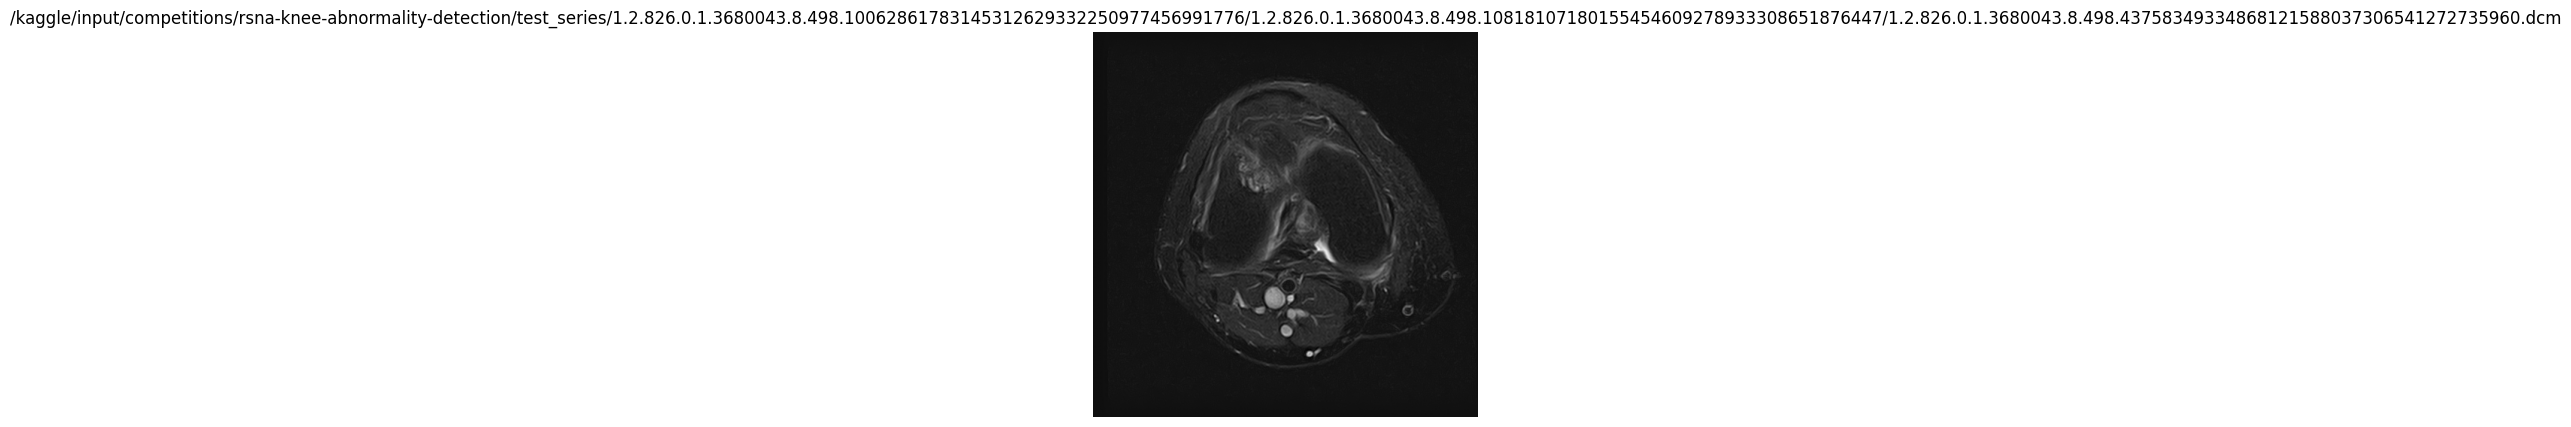

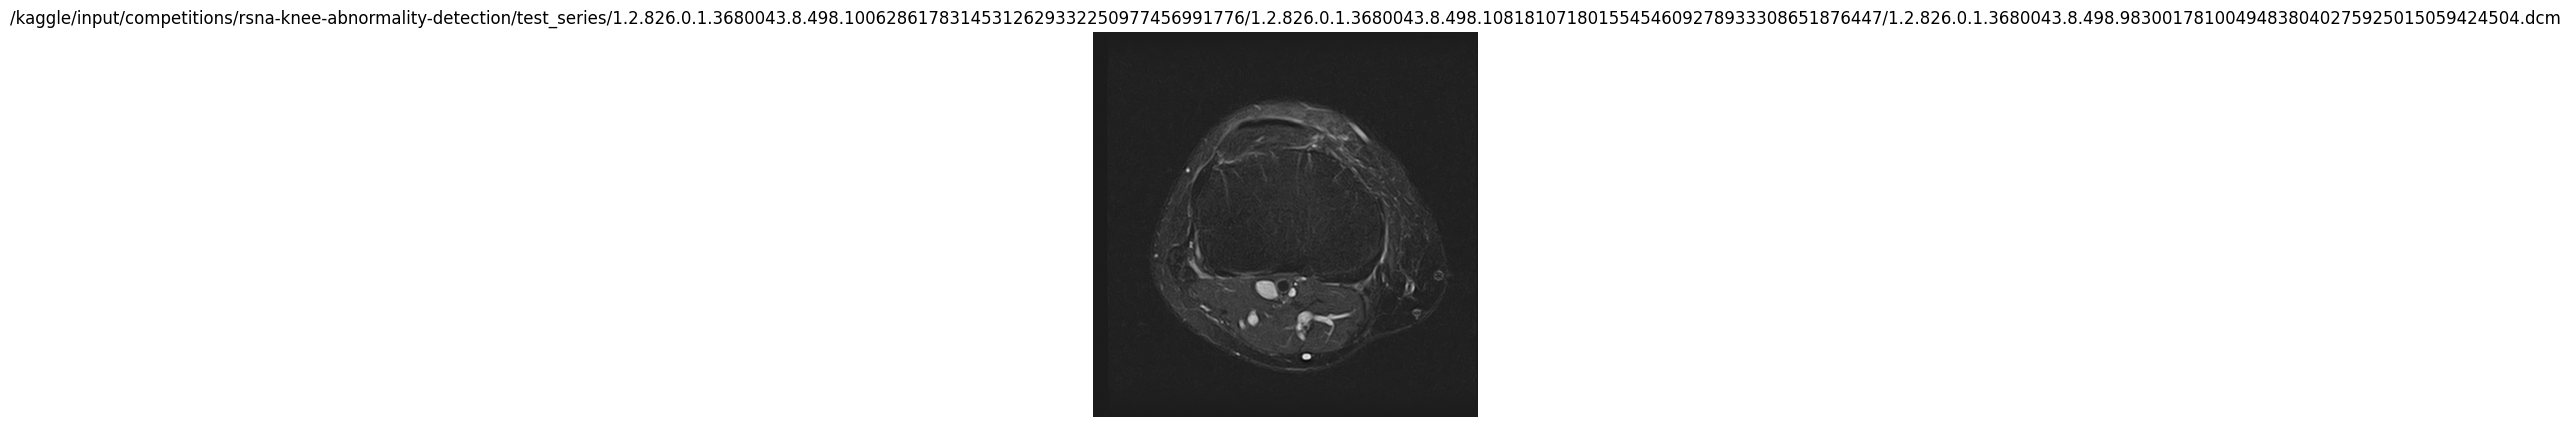

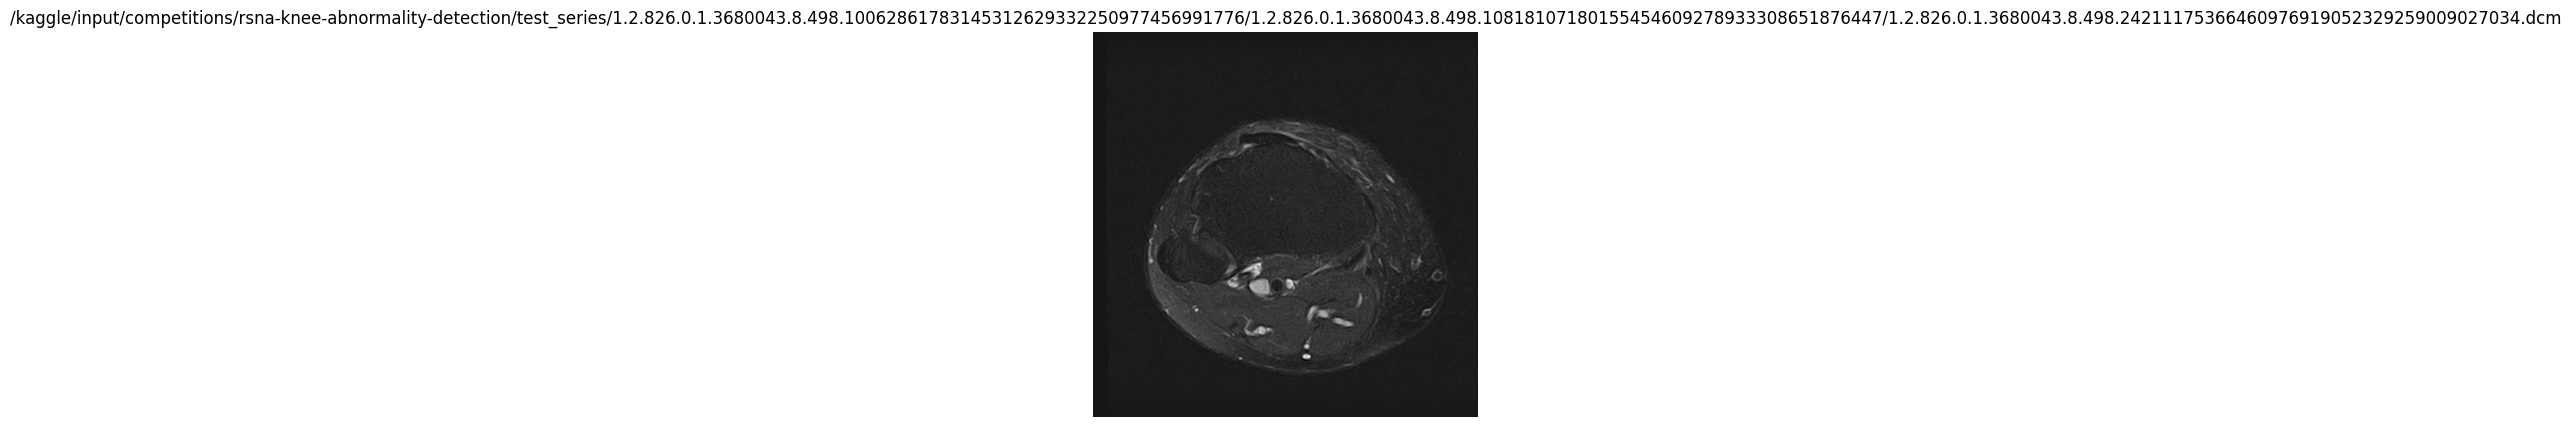

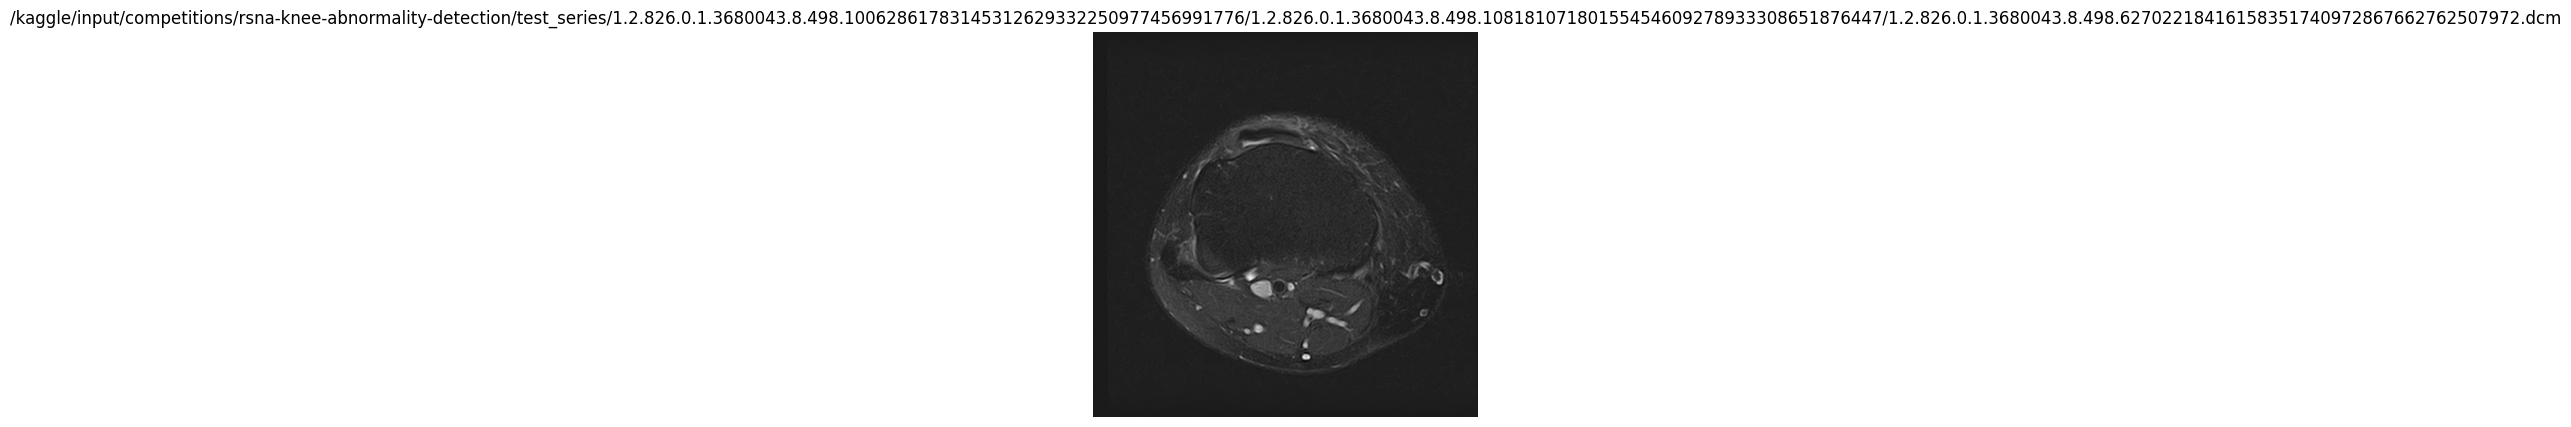

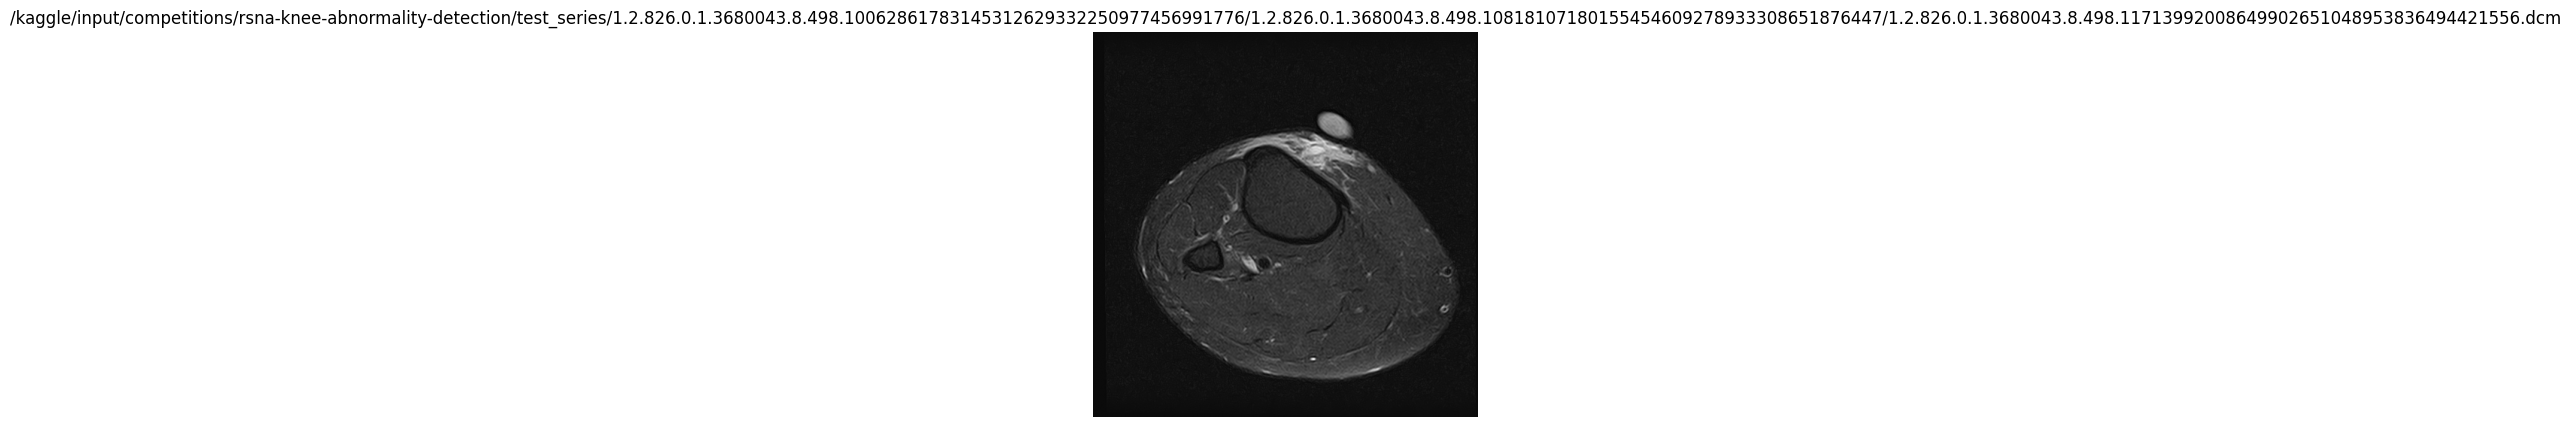

In [70]:
# Demeli sekillerin uzerinde olan idler- Series instance UID uzerinden aparir
import pydicom
import matplotlib.pyplot as plt

for file in dcm_files_test[:5]:
    dcm = pydicom.dcmread(file)
    image = dcm.pixel_array

    plt.figure(figsize=(5, 5))
    plt.imshow(image, cmap="gray")
    plt.title(file)
    plt.axis("off")
    plt.show()

# Test Dataset (Text)

In [71]:
test_dataset = pd.read_csv("/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series.csv")

In [72]:
len(test_dataset)

15

In [73]:
test_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   StudyInstanceUID   15 non-null     object
 1   SeriesInstanceUID  15 non-null     object
 2   Fluid_Sensitive    15 non-null     int64 
 3   Fat_Suppression    15 non-null     int64 
 4   Anatomical_Plane   15 non-null     object
dtypes: int64(2), object(3)
memory usage: 732.0+ bytes


In [74]:
train_ids = set(train_dataset["StudyInstanceUID"])
test_ids = set(test_dataset["StudyInstanceUID"])

overlap = train_ids & test_ids

print("Train IDs:", len(train_ids))
print("Test IDs:", len(test_ids))
print("Overlap:", len(overlap))

if overlap:
    print("Eyni ID-lər tapıldı:")
    print(list(overlap)[:10])

Train IDs: 4407
Test IDs: 3
Overlap: 0


In [75]:
test_dataset.shape

(15, 5)

# Submission File

In [76]:
submission_file = pd.read_csv("/kaggle/input/competitions/rsna-knee-abnormality-detection/sample_submission.csv")

In [77]:
submission_file.head()

,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5


In [78]:
len(submission_file)

3

In [79]:
submission_file.columns

Index(['StudyInstanceUID', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus',
       'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', 'Baker's',
       'Contusion', 'Fracture'],
      dtype='object')

In [80]:
submission_file['StudyInstanceUID']

0    1.2.826.0.1.3680043.8.498.10047035057544427318...
1    1.2.826.0.1.3680043.8.498.10062861783145312629...
2    1.2.826.0.1.3680043.8.498.10067514707072572280...
Name: StudyInstanceUID, dtype: object

## Creating my own tokenizer

In [81]:
import os

for root, dirs, files in os.walk("/kaggle/input/datasets/thesharifzade/pharmaconerdataset"):
    print(root)
    print(files[:10])

/kaggle/input/datasets/thesharifzade/pharmaconerdataset
[]
/kaggle/input/datasets/thesharifzade/pharmaconerdataset/pharmaco-ner
['dataset_dict.json']
/kaggle/input/datasets/thesharifzade/pharmaconerdataset/pharmaco-ner/validation
['state.json', 'dataset_info.json', 'data-00000-of-00001.arrow']
/kaggle/input/datasets/thesharifzade/pharmaconerdataset/pharmaco-ner/test
['state.json', 'dataset_info.json', 'data-00000-of-00001.arrow']
/kaggle/input/datasets/thesharifzade/pharmaconerdataset/pharmaco-ner/train
['state.json', 'dataset_info.json', 'data-00000-of-00001.arrow']


In [82]:
# so we use the sentencepiece
# download the dataset
from datasets import load_from_disk

cantemistnerdataset = load_from_disk(
    "/kaggle/input/datasets/thesharifzade/cantemistdatasetfile/cantemist-ner"
)

print(cantemistnerdataset)

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 19397
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 18165
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 11168
    })
})


In [83]:
# upload pharmaconerdataset
from datasets import load_from_disk
pharmaconerdataset = load_from_disk("/kaggle/input/datasets/thesharifzade/pharmaconerdataset/pharmaco-ner")
print(pharmaconerdataset)

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 8129
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 3787
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 3952
    })
})


In [84]:
from datasets import concatenate_datasets

train1 = cantemistnerdataset["train"].remove_columns(["ner_tags"])
train2 = pharmaconerdataset["train"].remove_columns(["ner_tags"])

train_ds = concatenate_datasets([
    train1,
    train2
])

print(train_ds)

Dataset({
    features: ['id', 'tokens'],
    num_rows: 27526
})


In [85]:
# train_ds artıq hazırdır

texts = [
    " ".join(example["tokens"])
    for example in train_ds
]

with open("/kaggle/working/cantemist_train.txt", "w", encoding="utf-8") as f:
    for text in texts:
        f.write(text + "\n")

print("Samples:", len(texts))
print(texts[0])

Samples: 27526
ANAMNESIS Mujer de 67 años con antecedentes personales de hipotiroidismo en tratamiento con levotiroxina y fumadora activa de 12.5 paquetes / año .


In [86]:
import sentencepiece as spm

spm.SentencePieceTrainer.train(
    input="/kaggle/working/cantemist_train.txt",
    model_prefix="/kaggle/working/cantemist_tokenizer",
    model_type="bpe",
    vocab_size=8000,
    character_coverage=0.99995,

    normalization_rule_name="identity",
    add_dummy_prefix=True,
    remove_extra_whitespaces=False,

    split_by_unicode_script=True,
    split_by_whitespace=True,
    split_by_number=True,
    split_digits=True,

    max_sentencepiece_length=16,
    allow_whitespace_only_pieces=True,
    byte_fallback=True,

    unk_id=0,
    bos_id=1,
    eos_id=2,
    pad_id=3,

    unk_piece="<unk>",
    bos_piece="<s>",
    eos_piece="</s>",
    pad_piece="<pad>",

    hard_vocab_limit=True,
    input_sentence_size=0,
    shuffle_input_sentence=True,
)

sentencepiece_trainer.cc(78) LOG(INFO) Starts training with : 
trainer_spec {
  input: /kaggle/working/cantemist_train.txt
  input_format: 
  model_prefix: /kaggle/working/cantemist_tokenizer
  model_type: BPE
  vocab_size: 8000
  self_test_sample_size: 0
  character_coverage: 0.99995
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 1
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 1
  required_chars: 
  byte_fallback: 1
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  eos_id: 2
  pad_id: 3
  unk_piece: <unk>
  bos_piece: <s>
  eos_piece: </s>
  pad_piece: <pad>
  unk_surface

In [87]:
sp = spm.SentencePieceProcessor(
    model_file="/kaggle/working/cantemist_tokenizer.model"
)

text = texts[0]

print(sp.encode(text, out_type=str))
print(sp.encode(text, out_type=int))

['▁ANA', 'MN', 'ES', 'IS', '▁Mujer', '▁de', '▁', '6', '7', '▁años', '▁con', '▁antecedentes', '▁personales', '▁de', '▁hipotiroidismo', '▁en', '▁tratamiento', '▁con', '▁levotiroxina', '▁y', '▁fumadora', '▁activa', '▁de', '▁', '1', '2', '.', '5', '▁paquetes', '▁/', '▁año', '▁.']
[4110, 4754, 2942, 4447, 1465, 262, 7898, 7948, 7953, 517, 286, 700, 1362, 262, 4612, 292, 372, 286, 5655, 291, 4144, 2820, 262, 7898, 7925, 7927, 7918, 7939, 3121, 371, 1479, 278]


cc(268) LOG(INFO) Added: freq=33 size=5020 all=40282 active=2078 piece=▁Col
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=33 size=5040 all=40359 active=2155 piece=▁lugar
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=33 size=5060 all=40395 active=2191 piece=▁artritis
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=33 size=5080 all=40398 active=2194 piece=▁hiponatremia
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=32 size=5100 all=40473 active=2269 piece=▁ag
bpe_model_trainer.cc(159) LOG(INFO) Updating active symbols. max_freq=32 min_freq=20
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=32 size=5120 all=40561 active=2107 piece=▁pli
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=32 size=5140 all=40627 active=2173 piece=▁Hasta
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=32 size=5160 all=40645 active=2191 piece=licación
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=32 size=5180 all=40653 active=2199 piece=▁endometri
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=32 size=5200

In [88]:
"""model = AutoModelForCausalLM.from_pretrained(
    ai_model,
    torch_dtype=torch.float16
)"""

'model = AutoModelForCausalLM.from_pretrained(\n    ai_model,\n    torch_dtype=torch.float16\n)'

In [89]:
"""qwen_messages = []

for item in qwen_data:
    qwen_messages.append({
        "messages": [
            {
                "role": "system",
                "content": (
                    "Read the medical report and predict the 12 labels. "
                    "For each label, output only 0 or 1."
                )
            },
            {
                "role": "user",
                "content": item["input"]
            },
            {
                "role": "assistant",
                "content": str(item["output"])
            }
        ]
    })

print(qwen_messages[0])"""

'qwen_messages = []\n\nfor item in qwen_data:\n    qwen_messages.append({\n        "messages": [\n            {\n                "role": "system",\n                "content": (\n                    "Read the medical report and predict the 12 labels. "\n                    "For each label, output only 0 or 1."\n                )\n            },\n            {\n                "role": "user",\n                "content": item["input"]\n            },\n            {\n                "role": "assistant",\n                "content": str(item["output"])\n            }\n        ]\n    })\n\nprint(qwen_messages[0])'

In [90]:
"""from datasets import Dataset

dataset = Dataset.from_list(qwen_messages)

print(dataset)"""

'from datasets import Dataset\n\ndataset = Dataset.from_list(qwen_messages)\n\nprint(dataset)'

In [91]:
"""def tokenize(example):
    text = ""

    for message in example["messages"]:
        text += message["content"] + "\n"

    input_ids = sp.encode(text, out_type=int)

    input_ids = input_ids[:1024]

    padding_length = 1024 - len(input_ids)

    input_ids += [0] * padding_length

    attention_mask = [1] * (1024 - padding_length) + [0] * padding_length

    labels = input_ids.copy()

    labels = [
        token if mask == 1 else -100
        for token, mask in zip(labels, attention_mask)
    ]

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }

tokenized_dataset = dataset.map(
    tokenize,
    remove_columns=dataset.column_names
)"""

'def tokenize(example):\n    text = ""\n\n    for message in example["messages"]:\n        text += message["content"] + "\n"\n\n    input_ids = sp.encode(text, out_type=int)\n\n    input_ids = input_ids[:1024]\n\n    padding_length = 1024 - len(input_ids)\n\n    input_ids += [0] * padding_length\n\n    attention_mask = [1] * (1024 - padding_length) + [0] * padding_length\n\n    labels = input_ids.copy()\n\n    labels = [\n        token if mask == 1 else -100\n        for token, mask in zip(labels, attention_mask)\n    ]\n\n    return {\n        "input_ids": input_ids,\n        "attention_mask": attention_mask,\n        "labels": labels\n    }\n\ntokenized_dataset = dataset.map(\n    tokenize,\n    remove_columns=dataset.column_names\n)'

In [92]:
"""print(tokenized_dataset[0]["input_ids"][:5])"""

'print(tokenized_dataset[0]["input_ids"][:5])'

In [93]:
"""# input ids -> result of tokenization(with ids)
# attention_mask -> which padding, which real token
# label -> the target
print(tokenized_dataset.column_names)
print(tokenized_dataset[0].keys())"""

'# input ids -> result of tokenization(with ids)\n# attention_mask -> which padding, which real token\n# label -> the target\nprint(tokenized_dataset.column_names)\nprint(tokenized_dataset[0].keys())'

In [94]:
"""print("input_ids:", len(tokenized_dataset[0]["input_ids"]))
print("attention_mask:", len(tokenized_dataset[0]["attention_mask"]))
print("labels:", len(tokenized_dataset[0]["labels"]))"""

'print("input_ids:", len(tokenized_dataset[0]["input_ids"]))\nprint("attention_mask:", len(tokenized_dataset[0]["attention_mask"]))\nprint("labels:", len(tokenized_dataset[0]["labels"]))'

In [95]:
"""# PEFT method : free entire LLM, add tiny layers
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ],
    bias="none",
    task_type="CAUSAL_LM"
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()
"""

'# PEFT method : free entire LLM, add tiny layers\nfrom peft import LoraConfig, get_peft_model\n\nlora_config = LoraConfig(\n    r=8,\n    lora_alpha=16,\n    lora_dropout=0.05,\n    target_modules=[\n        "q_proj",\n        "k_proj",\n        "v_proj",\n        "o_proj"\n    ],\n    bias="none",\n    task_type="CAUSAL_LM"\n)\n\nmodel = get_peft_model(model, lora_config)\n\nmodel.print_trainable_parameters()\n'

In [96]:
"""training_args = TrainingArguments(
    output_dir="./qwen_knee",
    num_train_epochs=2,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=32,
    learning_rate=2e-4,
    logging_steps=1,
    logging_strategy = "steps",
    save_strategy="epoch",
    fp16=True,
    report_to="none"
)"""

'training_args = TrainingArguments(\n    output_dir="./qwen_knee",\n    num_train_epochs=2,\n    per_device_train_batch_size=1,\n    gradient_accumulation_steps=32,\n    learning_rate=2e-4,\n    logging_steps=1,\n    logging_strategy = "steps",\n    save_strategy="epoch",\n    fp16=True,\n    report_to="none"\n)'

In [97]:
"""trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset,
)"""

'trainer = Trainer(\n    model=model,\n    args=training_args,\n    train_dataset=tokenized_dataset,\n)'

In [98]:
#trainer.train()

In [99]:
"""import matplotlib.pyplot as plt

logs = trainer.state.log_history

steps = []
losses = []

for log in logs:
    if "loss" in log:
        steps.append(log["step"])
        losses.append(log["loss"])

plt.plot(steps, losses)
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid()
plt.show()"""

'import matplotlib.pyplot as plt\n\nlogs = trainer.state.log_history\n\nsteps = []\nlosses = []\n\nfor log in logs:\n    if "loss" in log:\n        steps.append(log["step"])\n        losses.append(log["loss"])\n\nplt.plot(steps, losses)\nplt.xlabel("Training Steps")\nplt.ylabel("Loss")\nplt.title("Training Loss")\nplt.grid()\nplt.show()'

In [100]:
#print(trainer.state.log_history)

In [101]:
#trainer.save_model("./finetuningazesavedversion")

# Check the fine tuned version (is working yes or no?)

In [102]:
#file_path = "/kaggle/input/datasets/thesharifzade/finetuningazerbaijanversionrsnaknee/finetuningazesavedversion"

In [103]:
"""import os

print(os.listdir(file_path))"""

'import os\n\nprint(os.listdir(file_path))'

In [104]:
"""from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel

base_model = "/kaggle/input/models/qwen-lm/qwen2.5/transformers/1.5b/1"

tokenizer = AutoTokenizer.from_pretrained(base_model)

model = AutoModelForCausalLM.from_pretrained(
    base_model,
    torch_dtype="auto",
    device_map="auto"
)"""

'from transformers import AutoModelForCausalLM, AutoTokenizer\nfrom peft import PeftModel\n\nbase_model = "/kaggle/input/models/qwen-lm/qwen2.5/transformers/1.5b/1"\n\ntokenizer = AutoTokenizer.from_pretrained(base_model)\n\nmodel = AutoModelForCausalLM.from_pretrained(\n    base_model,\n    torch_dtype="auto",\n    device_map="auto"\n)'

In [105]:
"""
model = PeftModel.from_pretrained(
    model,
    file_path
)"""

'\nmodel = PeftModel.from_pretrained(\n    model,\n    file_path\n)'

In [106]:
"""prompt = "Your test prompt here"

inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

outputs = model.generate(
    **inputs,
    max_new_tokens=100
)

print(tokenizer.decode(outputs[0], skip_special_tokens=True))"""

'prompt = "Your test prompt here"\n\ninputs = tokenizer(prompt, return_tensors="pt").to(model.device)\n\noutputs = model.generate(\n    **inputs,\n    max_new_tokens=100\n)\n\nprint(tokenizer.decode(outputs[0], skip_special_tokens=True))'

# Check the fine tuned version for train labels with actual data and prediction 

In [107]:
#train_dataset = pd.read_csv("/kaggle/input/competitions/rsna-knee-abnormality-detection/train.csv")

In [108]:
"""# yalnız 12 label-i olan 58 sətri götürəcəyik
labeled_data = train_dataset.dropna()

print(labeled_data.shape)"""

'# yalnız 12 label-i olan 58 sətri götürəcəyik\nlabeled_data = train_dataset.dropna()\n\nprint(labeled_data.shape)'

In [109]:
"""labels = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture"
]

qwen_data = []

for _, row in labeled_data.iterrows():
    qwen_data.append({
        "input": row["Report"],
        "output": {label: int(row[label]) for label in labels}
    })

print(qwen_data[0])"""

'labels = [\n    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",\n    "Medial OA", "Lateral OA", "PF OA", "Effusion",\n    "Synovitis", "Baker\'s", "Contusion", "Fracture"\n]\n\nqwen_data = []\n\nfor _, row in labeled_data.iterrows():\n    qwen_data.append({\n        "input": row["Report"],\n        "output": {label: int(row[label]) for label in labels}\n    })\n\nprint(qwen_data[0])'

In [110]:
"""qwen_messages = []

for item in qwen_data:
    qwen_messages.append({
        "messages": [
            {
                "role": "system",
                "content": (
                    "Read the medical report and predict the 12 labels. "
                    "For each label, output only 0 or 1."
                )
            },
            {
                "role": "user",
                "content": item["input"]
            },
            {
                "role": "assistant",
                "content": str(item["output"])
            }
        ]
    })

print(qwen_messages[0])"""

'qwen_messages = []\n\nfor item in qwen_data:\n    qwen_messages.append({\n        "messages": [\n            {\n                "role": "system",\n                "content": (\n                    "Read the medical report and predict the 12 labels. "\n                    "For each label, output only 0 or 1."\n                )\n            },\n            {\n                "role": "user",\n                "content": item["input"]\n            },\n            {\n                "role": "assistant",\n                "content": str(item["output"])\n            }\n        ]\n    })\n\nprint(qwen_messages[0])'

In [111]:
"""from datasets import Dataset, concatenate_datasets

# 1. Qwen dataset
dataset = Dataset.from_list(qwen_messages)

print(dataset)"""

'from datasets import Dataset, concatenate_datasets\n\n# 1. Qwen dataset\ndataset = Dataset.from_list(qwen_messages)\n\nprint(dataset)'

In [112]:
"""import sentencepiece as spm

spm.SentencePieceTrainer.train(
    input="/kaggle/working/cantemist_train.txt",
    model_prefix="/kaggle/working/cantemist_tokenizer",
    model_type="bpe",
    vocab_size=8000,
    character_coverage=0.99995,

    normalization_rule_name="identity",
    add_dummy_prefix=True,
    remove_extra_whitespaces=False,

    split_by_unicode_script=True,
    split_by_whitespace=True,
    split_by_number=True,
    split_digits=True,

    max_sentencepiece_length=16,
    allow_whitespace_only_pieces=True,
    byte_fallback=True,

    unk_id=0,
    bos_id=1,
    eos_id=2,
    pad_id=3,

    unk_piece="<unk>",
    bos_piece="<s>",
    eos_piece="</s>",
    pad_piece="<pad>",

    hard_vocab_limit=True,
    input_sentence_size=0,
    shuffle_input_sentence=True,
)"""

'import sentencepiece as spm\n\nspm.SentencePieceTrainer.train(\n    input="/kaggle/working/cantemist_train.txt",\n    model_prefix="/kaggle/working/cantemist_tokenizer",\n    model_type="bpe",\n    vocab_size=8000,\n    character_coverage=0.99995,\n\n    normalization_rule_name="identity",\n    add_dummy_prefix=True,\n    remove_extra_whitespaces=False,\n\n    split_by_unicode_script=True,\n    split_by_whitespace=True,\n    split_by_number=True,\n    split_digits=True,\n\n    max_sentencepiece_length=16,\n    allow_whitespace_only_pieces=True,\n    byte_fallback=True,\n\n    unk_id=0,\n    bos_id=1,\n    eos_id=2,\n    pad_id=3,\n\n    unk_piece="<unk>",\n    bos_piece="<s>",\n    eos_piece="</s>",\n    pad_piece="<pad>",\n\n    hard_vocab_limit=True,\n    input_sentence_size=0,\n    shuffle_input_sentence=True,\n)'

In [113]:
"""sp = spm.SentencePieceProcessor(
    model_file="/kaggle/working/cantemist_tokenizer.model"
)

text = texts[0]

print(sp.encode(text, out_type=str))
print(sp.encode(text, out_type=int))"""

'sp = spm.SentencePieceProcessor(\n    model_file="/kaggle/working/cantemist_tokenizer.model"\n)\n\ntext = texts[0]\n\nprint(sp.encode(text, out_type=str))\nprint(sp.encode(text, out_type=int))'

In [114]:
"""def tokenize(example):
    text = ""

    for message in example["messages"]:
        text += message["content"] + "\n"

    input_ids = sp.encode(text, out_type=int)

    input_ids = input_ids[:1024]

    padding_length = 1024 - len(input_ids)

    input_ids += [0] * padding_length

    attention_mask = [1] * (1024 - padding_length) + [0] * padding_length

    labels = input_ids.copy()

    labels = [
        token if mask == 1 else -100
        for token, mask in zip(labels, attention_mask)
    ]

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }

tokenized_dataset = dataset.map(
    tokenize,
    remove_columns=dataset.column_names
)"""

'def tokenize(example):\n    text = ""\n\n    for message in example["messages"]:\n        text += message["content"] + "\n"\n\n    input_ids = sp.encode(text, out_type=int)\n\n    input_ids = input_ids[:1024]\n\n    padding_length = 1024 - len(input_ids)\n\n    input_ids += [0] * padding_length\n\n    attention_mask = [1] * (1024 - padding_length) + [0] * padding_length\n\n    labels = input_ids.copy()\n\n    labels = [\n        token if mask == 1 else -100\n        for token, mask in zip(labels, attention_mask)\n    ]\n\n    return {\n        "input_ids": input_ids,\n        "attention_mask": attention_mask,\n        "labels": labels\n    }\n\ntokenized_dataset = dataset.map(\n    tokenize,\n    remove_columns=dataset.column_names\n)'

In [115]:
"""# input ids -> result of tokenization(with ids)
# attention_mask -> which padding, which real token
# label -> the target
print(tokenized_dataset.column_names)
print(tokenized_dataset[0].keys())"""

'# input ids -> result of tokenization(with ids)\n# attention_mask -> which padding, which real token\n# label -> the target\nprint(tokenized_dataset.column_names)\nprint(tokenized_dataset[0].keys())'

In [116]:
#print(tokenized_dataset[0]["input_ids"][:5])

In [117]:
#print(tokenized_dataset[0]["attention_mask"][:5])
#print(tokenized_dataset[0]["labels"][:5])

In [118]:
# Test report terefde problem var labeller oyrenmeyib ona gore bele raw text cixarib 
"""
'Antecedentes Clínicos:\nEsguince rodilla. [DATE].\nHallazgos:\nNo hay alteraciones de señal significativas de la médula ósea.\nLigamentos cruzados y colaterales dentro de límites normales.\nAmputación marginal del cuerpo del menisco lateral. Menisco medial de morfología y señal\nconservada, sin signos de rotura.\nCartílagos de los compartimentos femorotibiales sin alteraciones.\nFina úlcera condral focal de espesor total del aspecto inferior de la vertiente medial de la tróclea\nfemoral con mínimos cambios óseos secundarios. Fenómenos condrales reparativos de la región\ncentral de la simple femoral. Cartílago rotuliano sin alteraciones.\nLeve derrame articular. No hay quistes poplíteos patológicos.\nAumento de señal de la inserción distal del tendón cuadricipital y de la inserción proximal del\ntendón rotuliano, sin signos de rotura.\nNo hay alteraciones de señal de la grasa de Hoffa.\nImpresión:\nAmputación marginal del cuerpo del menisco lateral.\nCondropatía focal grado 4 del aspecto inferior de la vertiente medial de la tróclea femoral .\nFenómenos condrales reparativos de la región central de la tróclea femoral.\nLeve derrame articular.\nLeve tendinosis cuadricipital distal y rotuliana proximal.

"""

"\n'Antecedentes Clínicos:\nEsguince rodilla. [DATE].\nHallazgos:\nNo hay alteraciones de señal significativas de la médula ósea.\nLigamentos cruzados y colaterales dentro de límites normales.\nAmputación marginal del cuerpo del menisco lateral. Menisco medial de morfología y señal\nconservada, sin signos de rotura.\nCartílagos de los compartimentos femorotibiales sin alteraciones.\nFina úlcera condral focal de espesor total del aspecto inferior de la vertiente medial de la tróclea\nfemoral con mínimos cambios óseos secundarios. Fenómenos condrales reparativos de la región\ncentral de la simple femoral. Cartílago rotuliano sin alteraciones.\nLeve derrame articular. No hay quistes poplíteos patológicos.\nAumento de señal de la inserción distal del tendón cuadricipital y de la inserción proximal del\ntendón rotuliano, sin signos de rotura.\nNo hay alteraciones de señal de la grasa de Hoffa.\nImpresión:\nAmputación marginal del cuerpo del menisco lateral.\nCondropatía focal grado 4 del as

In [119]:
#qwen_data[0]["output"]

In [120]:
#test_report = qwen_data[0]["input"]

In [121]:
#test_report

# Analysis more bigger version of qwen

In [122]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
import seaborn as sns
from transformers import TrainingArguments, Trainer

In [123]:
import kagglehub

# Download latest version
path = kagglehub.model_download("qwen-lm/qwen2.5/transformers/7b")

print("Path to model files:", path)

Path to model files: /kaggle/input/models/qwen-lm/qwen2.5/transformers/7b/1


In [124]:
# quantized version edirik yeni bir novu modelin icindeki parameterler terefden evvel 16 bit tam formatda verirdise
# indi 4 bit formatinda verecek, hesablamalar terefden ozunu zeif apara biler, amma dusunme terefden guclu aparacagina inaniriq



In [125]:
#!ls -lh /kaggle/input/datasets/thesharifzade/bitsandbytesrsnaazerbaijan

In [126]:
#!ls -lh /kaggle/input/datasets/thesharifzade/bitsandbytesrsnaazerbaijan/wheels

In [127]:
#!pip uninstall -y bitsandbytes

In [128]:
!pip install --no-index --no-deps \
    --find-links=/kaggle/input/datasets/thesharifzade/bitsandbytesrsnaazerbaijan/wheels \
    bitsandbytes==0.50.2

Looking in links: /kaggle/input/datasets/thesharifzade/bitsandbytesrsnaazerbaijan/wheels
Processing /kaggle/input/datasets/thesharifzade/bitsandbytesrsnaazerbaijan/wheels/bitsandbytes-0.50.2-py3-none-manylinux_2_24_x86_64.whl


In [129]:
import bitsandbytes as bnb
print(bnb.__version__)

0.50.2


In [130]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
import seaborn as sns
from transformers import TrainingArguments, Trainer

In [131]:
!pip install --no-index "/kaggle/input/datasets/thesharifzade/torchao/torchao_pkg/torchao-0.16.0-cp310-abi3-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl"

Processing /kaggle/input/datasets/thesharifzade/torchao/torchao_pkg/torchao-0.16.0-cp310-abi3-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl
torchao is already installed with the same version as the provided wheel. Use --force-reinstall to force an installation of the wheel.


In [132]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

model_name = path

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(model_name) # tokenizer from qwen 14b

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=quant_config,
    device_map="auto"
)

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

In [133]:
tokenizer

Qwen2Tokenizer(name_or_path='/kaggle/input/models/qwen-lm/qwen2.5/transformers/7b/1', vocab_size=151643, model_max_length=131072, padding_side='right', truncation_side='right', special_tokens={'eos_token': '<|endoftext|>', 'pad_token': '<|endoftext|>'}, added_tokens_decoder={
	151643: AddedToken("<|endoftext|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151644: AddedToken("<|im_start|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151645: AddedToken("<|im_end|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151646: AddedToken("<|object_ref_start|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151647: AddedToken("<|object_ref_end|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151648: AddedToken("<|box_start|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151649: Adde

In [134]:
import os

for root, dirs, files in os.walk("/kaggle/input/datasets/thesharifzade/pharmaconerdataset"):
    print(root)
    print(files[:10])

/kaggle/input/datasets/thesharifzade/pharmaconerdataset
[]
/kaggle/input/datasets/thesharifzade/pharmaconerdataset/pharmaco-ner
['dataset_dict.json']
/kaggle/input/datasets/thesharifzade/pharmaconerdataset/pharmaco-ner/validation
['state.json', 'dataset_info.json', 'data-00000-of-00001.arrow']
/kaggle/input/datasets/thesharifzade/pharmaconerdataset/pharmaco-ner/test
['state.json', 'dataset_info.json', 'data-00000-of-00001.arrow']
/kaggle/input/datasets/thesharifzade/pharmaconerdataset/pharmaco-ner/train
['state.json', 'dataset_info.json', 'data-00000-of-00001.arrow']


In [135]:
train_dataset = pd.read_csv("/kaggle/input/competitions/rsna-knee-abnormality-detection/train.csv")

In [136]:
# yalnız 12 label-i olan 58 sətri götürəcəyik
labeled_data = train_dataset.dropna()

print(labeled_data.shape)

(58, 14)


In [137]:
train_dataset[:5]

,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,Técnica: RMN de la rodilla. Resultados: Rotura...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,[DATE]: * MR Knie Rechts 15ch AA Klinische Inl...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,Hallazgos:\nNo hay alteraciones en significati...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,"In the medial compartment, the meniscus is no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,CONSTATATIONS :\n\nFractures :\nAucune.\n\nAli...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [138]:
labels = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture"
]

qwen_data = []

for _, row in labeled_data.iterrows():
    qwen_data.append({
        "input": row["Report"],
        "output": {label: int(row[label]) for label in labels}
    })

print(qwen_data[0])

{'input': 'Antecedentes Clínicos:\nEsguince rodilla. [DATE].\nHallazgos:\nNo hay alteraciones de señal significativas de la médula ósea.\nLigamentos cruzados y colaterales dentro de límites normales.\nAmputación marginal del cuerpo del menisco lateral. Menisco medial de morfología y señal\nconservada, sin signos de rotura.\nCartílagos de los compartimentos femorotibiales sin alteraciones.\nFina úlcera condral focal de espesor total del aspecto inferior de la vertiente medial de la tróclea\nfemoral con mínimos cambios óseos secundarios. Fenómenos condrales reparativos de la región\ncentral de la simple femoral. Cartílago rotuliano sin alteraciones.\nLeve derrame articular. No hay quistes poplíteos patológicos.\nAumento de señal de la inserción distal del tendón cuadricipital y de la inserción proximal del\ntendón rotuliano, sin signos de rotura.\nNo hay alteraciones de señal de la grasa de Hoffa.\nImpresión:\nAmputación marginal del cuerpo del menisco lateral.\nCondropatía focal grado 4

In [139]:
import json

example = qwen_data[0]

messages = [
    {
        "role": "system",
        "content": """
Read a medical knee MRI report and output exactly 12 labels as JSON.
Use only 0 or 1.

The labels must be exactly:
ACL, MCL, Medial Meniscus, Lateral Meniscus, Medial OA,
Lateral OA, PF OA, Effusion, Synovitis, Baker's, Contusion, Fracture.
"""
    },
    {
        "role": "user",
        "content": example["input"]
    },
    {
        "role": "assistant",
        "content": json.dumps(example["output"])
    }
]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=False
)

print(text)

<|im_start|>system

Read a medical knee MRI report and output exactly 12 labels as JSON.
Use only 0 or 1.

The labels must be exactly:
ACL, MCL, Medial Meniscus, Lateral Meniscus, Medial OA,
Lateral OA, PF OA, Effusion, Synovitis, Baker's, Contusion, Fracture.
<|im_end|>
<|im_start|>user
Antecedentes Clínicos:
Esguince rodilla. [DATE].
Hallazgos:
No hay alteraciones de señal significativas de la médula ósea.
Ligamentos cruzados y colaterales dentro de límites normales.
Amputación marginal del cuerpo del menisco lateral. Menisco medial de morfología y señal
conservada, sin signos de rotura.
Cartílagos de los compartimentos femorotibiales sin alteraciones.
Fina úlcera condral focal de espesor total del aspecto inferior de la vertiente medial de la tróclea
femoral con mínimos cambios óseos secundarios. Fenómenos condrales reparativos de la región
central de la simple femoral. Cartílago rotuliano sin alteraciones.
Leve derrame articular. No hay quistes poplíteos patológicos.
Aumento de señ

In [140]:
tokens = tokenizer(
    text,
    truncation=True,
    max_length=1024,
    padding=False
)

print(tokens.keys())
print(tokens["input_ids"][:20])
print("Number of tokens:", len(tokens["input_ids"]))

KeysView({'input_ids': [151644, 8948, 271, 4418, 264, 6457, 21381, 51360, 1895, 323, 2550, 6896, 220, 16, 17, 9201, 438, 4718, 624, 10253, 1172, 220, 15, 476, 220, 16, 382, 785, 9201, 1969, 387, 6896, 510, 55393, 11, 386, 3140, 11, 3264, 530, 11012, 3427, 355, 11, 444, 19165, 11012, 3427, 355, 11, 3264, 530, 80442, 345, 43, 19165, 80442, 11, 28415, 80442, 11, 30022, 7560, 11, 23153, 859, 19435, 11, 28392, 594, 11, 2093, 7560, 11, 2869, 531, 552, 624, 151645, 198, 151644, 872, 198, 17117, 58357, 21243, 2435, 2426, 84430, 510, 36, 1991, 84, 1701, 20589, 6241, 13, 508, 7097, 26126, 71845, 1370, 34073, 510, 2753, 17669, 11596, 12430, 409, 132456, 4595, 51541, 409, 1187, 33930, 5607, 40867, 36441, 624, 43, 343, 36779, 86151, 5553, 379, 1375, 962, 3831, 35128, 409, 31750, 91499, 7465, 3831, 624, 6091, 628, 5721, 31773, 1594, 62513, 1594, 2953, 9464, 44469, 13, 11012, 9464, 96248, 409, 4313, 69, 53333, 379, 132456, 198, 6254, 648, 2584, 11, 7437, 1841, 436, 409, 5749, 5690, 624, 12593, 2426, 

In [141]:
decoded = tokenizer.decode(
    tokens["input_ids"],
    skip_special_tokens=False
)

print(decoded)

<|im_start|>system

Read a medical knee MRI report and output exactly 12 labels as JSON.
Use only 0 or 1.

The labels must be exactly:
ACL, MCL, Medial Meniscus, Lateral Meniscus, Medial OA,
Lateral OA, PF OA, Effusion, Synovitis, Baker's, Contusion, Fracture.
<|im_end|>
<|im_start|>user
Antecedentes Clínicos:
Esguince rodilla. [DATE].
Hallazgos:
No hay alteraciones de señal significativas de la médula ósea.
Ligamentos cruzados y colaterales dentro de límites normales.
Amputación marginal del cuerpo del menisco lateral. Menisco medial de morfología y señal
conservada, sin signos de rotura.
Cartílagos de los compartimentos femorotibiales sin alteraciones.
Fina úlcera condral focal de espesor total del aspecto inferior de la vertiente medial de la tróclea
femoral con mínimos cambios óseos secundarios. Fenómenos condrales reparativos de la región
central de la simple femoral. Cartílago rotuliano sin alteraciones.
Leve derrame articular. No hay quistes poplíteos patológicos.
Aumento de señ

In [142]:
import json

def tokenize(example):

    messages = [
        {
            "role": "system",
            "content": """
Read a medical knee MRI report and output exactly 12 labels as JSON.
Use only 0 or 1.

The labels must be exactly:
ACL, MCL, Medial Meniscus, Lateral Meniscus, Medial OA,
Lateral OA, PF OA, Effusion, Synovitis, Baker's, Contusion, Fracture.
"""
        },
        {
            "role": "user",
            "content": example["input"]
        },
        {
            "role": "assistant",
            "content": json.dumps(example["output"])
        }
    ]

    # FULL conversation
    full_text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )

    # PROMPT only + assistant start
    prompt_text = tokenizer.apply_chat_template(
        messages[:-1],
        tokenize=False,
        add_generation_prompt=True
    )

    # Convert to normal Python lists
    full_ids = tokenizer(
        full_text,
        add_special_tokens=False
    )["input_ids"]

    prompt_ids = tokenizer(
        prompt_text,
        add_special_tokens=False
    )["input_ids"]

    max_length = 1024

    # Keep prompt + assistant response
    full_ids = full_ids[:max_length]
    prompt_length = min(len(prompt_ids), len(full_ids))

    # Only assistant tokens get loss
    labels = (
        [-100] * prompt_length
        + full_ids[prompt_length:]
    )

    attention_mask = [1] * len(full_ids)

    # Padding
    padding_length = max_length - len(full_ids)

    full_ids += [tokenizer.pad_token_id] * padding_length
    attention_mask += [0] * padding_length
    labels += [-100] * padding_length

    return {
        "input_ids": [int(x) for x in full_ids],
        "attention_mask": [int(x) for x in attention_mask],
        "labels": [int(x) for x in labels]
    }

In [143]:
from datasets import Dataset

dataset = Dataset.from_list(qwen_data)

In [144]:
from datasets import Dataset

dataset = Dataset.from_list(qwen_data)

tokenized_dataset = dataset.map(
    tokenize,
    remove_columns=dataset.column_names
)

print(tokenized_dataset.column_names)

Map:   0%|          | 0/58 [00:00<?, ? examples/s]

['input_ids', 'attention_mask', 'labels']


In [145]:
x = tokenized_dataset[0]

label_ids = [
    token for token in x["labels"]
    if token != -100
]

print(tokenizer.decode(
    label_ids,
    skip_special_tokens=False
))

{"ACL": 0, "MCL": 0, "Medial Meniscus": 0, "Lateral Meniscus": 0, "Medial OA": 0, "Lateral OA": 0, "PF OA": 1, "Effusion": 1, "Synovitis": 0, "Baker's": 0, "Contusion": 0, "Fracture": 0}<|im_end|>



In [146]:
import torch

from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training,
)

from transformers import (
    TrainingArguments,
    Trainer,
    default_data_collator,
)

In [147]:
model = prepare_model_for_kbit_training(model)

In [148]:
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj",
    ],
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

trainable params: 40,370,176 || all params: 7,655,986,688 || trainable%: 0.5273


In [149]:
training_args = TrainingArguments(
    output_dir="./qwen_knee_lora",

    num_train_epochs=3,

    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,

    learning_rate=2e-4,

    fp16=True,

    logging_steps=10,

    save_strategy="epoch",
    save_total_limit=2,

    report_to="none",

    optim="paged_adamw_8bit",

    remove_unused_columns=False,

    gradient_checkpointing=True,
)

In [150]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset,
    data_collator=default_data_collator,
)

In [151]:
trainer.train()

Step,Training Loss
10,0.172276
20,0.118734


TrainOutput(global_step=24, training_loss=0.14061581964294115, metrics={'train_runtime': 670.8154, 'train_samples_per_second': 0.259, 'train_steps_per_second': 0.036, 'total_flos': 7602045789929472.0, 'train_loss': 0.14061581964294115, 'epoch': 3.0})

In [152]:
trainer.save_model("./qwen_knee_lora")
tokenizer.save_pretrained("./qwen_knee_lora")

('./qwen_knee_lora/tokenizer_config.json',
 './qwen_knee_lora/chat_template.jinja',
 './qwen_knee_lora/tokenizer.json')

In [153]:
import json
import torch

test_report = qwen_data[1]["input"]

messages = [
    {
        "role": "system",
        "content": """
Read a medical knee MRI report and output exactly 12 labels as JSON.
Use only 0 or 1.

The labels must be exactly:
ACL, MCL, Medial Meniscus, Lateral Meniscus, Medial OA,
Lateral OA, PF OA, Effusion, Synovitis, Baker's, Contusion, Fracture.

Output ONLY the JSON object.
Do not write anything before or after the JSON.
"""
    },
    {
        "role": "user",
        "content": test_report
    }
]

prompt = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(
    prompt,
    return_tensors="pt"
).to(trainer.model.device)

trainer.model.eval()

with torch.no_grad():
    outputs = trainer.model.generate(
        **inputs,
        max_new_tokens=80,
        do_sample=False,
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.eos_token_id
    )

new_tokens = outputs[0][inputs["input_ids"].shape[1]:]

response = tokenizer.decode(
    new_tokens,
    skip_special_tokens=True
)

print("RAW:")
print(response)

RAW:
{"ACL": 0, "MCL": 0, "Medial Meniscus": 0, "Lateral Meniscus": 1, "Medial OA": 0, "Lateral OA": 1, "PF OA": 1, "Effusion": 1, "Synovitis": 1, "Baker's": 0, "


# Submission file

In [154]:
test = pd.read_csv("/kaggle/input/competitions/rsna-knee-abnormality-detection/test.csv")
test_series = pd.read_csv("/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series.csv")
print(test.shape)
study_id = test["StudyInstanceUID"].iloc[0]
test_series[test_series["StudyInstanceUID"] == study_id]

(3, 1)


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,1.2.826.0.1.3680043.8.498.11580656442259111255...,0,0,Axial
1,1.2.826.0.1.3680043.8.498.10047035057544427318...,1.2.826.0.1.3680043.8.498.17811502614030631664...,0,0,Sagittal
2,1.2.826.0.1.3680043.8.498.10047035057544427318...,1.2.826.0.1.3680043.8.498.30565395595045942404...,0,0,Sagittal
3,1.2.826.0.1.3680043.8.498.10047035057544427318...,1.2.826.0.1.3680043.8.498.32856494541816845805...,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10047035057544427318...,1.2.826.0.1.3680043.8.498.44334485654554877495...,1,1,Axial


In [155]:
import pandas as pd
import os

df = pd.read_csv(
    "/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series.csv"
)

train_path = "/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series"

row = df.iloc[0]

study_id = row["StudyInstanceUID"]
series_id = row["SeriesInstanceUID"]

series_path = os.path.join(train_path, study_id, series_id)

print("Series:", series_id)
print("Folder exists:", os.path.exists(series_path))
print("DICOM count:", len([f for f in os.listdir(series_path) if f.endswith(".dcm")]))

Series: 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
Folder exists: True
DICOM count: 22


In [156]:
import pandas as pd
import os

test = pd.read_csv(
    "/kaggle/input/competitions/rsna-knee-abnormality-detection/test.csv"
)

test_series = pd.read_csv(
    "/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series.csv"
)

test_path = "/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series"

# test.csv-dəki StudyInstanceUID-lərdən birini götür
study_id = test["StudyInstanceUID"].iloc[0]

# həmin StudyInstanceUID-yə aid bütün series-ləri tap
rows = test_series[test_series["StudyInstanceUID"] == study_id]

print("Study:", study_id)
print(rows)

Study: 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
                                    StudyInstanceUID  \
0  1.2.826.0.1.3680043.8.498.10047035057544427318...   
1  1.2.826.0.1.3680043.8.498.10047035057544427318...   
2  1.2.826.0.1.3680043.8.498.10047035057544427318...   
3  1.2.826.0.1.3680043.8.498.10047035057544427318...   
4  1.2.826.0.1.3680043.8.498.10047035057544427318...   

                                   SeriesInstanceUID  Fluid_Sensitive  \
0  1.2.826.0.1.3680043.8.498.11580656442259111255...                0   
1  1.2.826.0.1.3680043.8.498.17811502614030631664...                0   
2  1.2.826.0.1.3680043.8.498.30565395595045942404...                0   
3  1.2.826.0.1.3680043.8.498.32856494541816845805...                1   
4  1.2.826.0.1.3680043.8.498.44334485654554877495...                1   

   Fat_Suppression Anatomical_Plane  
0                0            Axial  
1                0         Sagittal  
2                0         Sagittal  


In [157]:
study_id = test.iloc[0]["StudyInstanceUID"]
print(study_id)

1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191


In [158]:
study_series = test_series[
    test_series["StudyInstanceUID"] == study_id
]

print(study_series)

                                    StudyInstanceUID  \
0  1.2.826.0.1.3680043.8.498.10047035057544427318...   
1  1.2.826.0.1.3680043.8.498.10047035057544427318...   
2  1.2.826.0.1.3680043.8.498.10047035057544427318...   
3  1.2.826.0.1.3680043.8.498.10047035057544427318...   
4  1.2.826.0.1.3680043.8.498.10047035057544427318...   

                                   SeriesInstanceUID  Fluid_Sensitive  \
0  1.2.826.0.1.3680043.8.498.11580656442259111255...                0   
1  1.2.826.0.1.3680043.8.498.17811502614030631664...                0   
2  1.2.826.0.1.3680043.8.498.30565395595045942404...                0   
3  1.2.826.0.1.3680043.8.498.32856494541816845805...                1   
4  1.2.826.0.1.3680043.8.498.44334485654554877495...                1   

   Fat_Suppression Anatomical_Plane  
0                0            Axial  
1                0         Sagittal  
2                0         Sagittal  
3                1          Coronal  
4                1            Axia

In [159]:
study_series

,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,1.2.826.0.1.3680043.8.498.11580656442259111255...,0,0,Axial
1,1.2.826.0.1.3680043.8.498.10047035057544427318...,1.2.826.0.1.3680043.8.498.17811502614030631664...,0,0,Sagittal
2,1.2.826.0.1.3680043.8.498.10047035057544427318...,1.2.826.0.1.3680043.8.498.30565395595045942404...,0,0,Sagittal
3,1.2.826.0.1.3680043.8.498.10047035057544427318...,1.2.826.0.1.3680043.8.498.32856494541816845805...,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10047035057544427318...,1.2.826.0.1.3680043.8.498.44334485654554877495...,1,1,Axial


In [160]:
for _, row in study_series.iterrows():

    series_id = row["SeriesInstanceUID"]

    print("Study:", study_id)
    print("Series:", series_id)

Study: 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
Series: 1.2.826.0.1.3680043.8.498.11580656442259111255675562605155903947
Study: 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
Series: 1.2.826.0.1.3680043.8.498.17811502614030631664517622518906646132
Study: 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
Series: 1.2.826.0.1.3680043.8.498.30565395595045942404081022062489758495
Study: 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
Series: 1.2.826.0.1.3680043.8.498.32856494541816845805947850304653662081
Study: 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
Series: 1.2.826.0.1.3680043.8.498.44334485654554877495800965096767429689


In [161]:
series_path = os.path.join(
    test_path,
    study_id,
    series_id
)

print(series_path)

/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series/1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191/1.2.826.0.1.3680043.8.498.44334485654554877495800965096767429689


In [162]:
dcm_files = sorted([
    f for f in os.listdir(series_path)
    if f.endswith(".dcm")
])

print("DICOM sayı:", len(dcm_files))
print(dcm_files[:5])

DICOM sayı: 160
['1.2.826.0.1.3680043.8.498.10011401452235111012351785365190316860.dcm', '1.2.826.0.1.3680043.8.498.10202433719972900087194428871975668016.dcm', '1.2.826.0.1.3680043.8.498.10404626347768649097085138311161430876.dcm', '1.2.826.0.1.3680043.8.498.10661663198283557849442476316173781956.dcm', '1.2.826.0.1.3680043.8.498.10926208741019080908531431475587103987.dcm']


In [163]:
new_train_file = pd.read_csv("/kaggle/input/datasets/thesharifzade/newtrainfile/new_train_checkpoint.csv")

In [164]:
# ===================== SUBMISSION: DINOv2 features + KneeClassifier =====================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import pydicom
from PIL import Image
from transformers import AutoImageProcessor, AutoModel


# ===================== SETTINGS =====================

COMP = "/kaggle/input/competitions/rsna-knee-abnormality-detection"
DINO_PATH = "/kaggle/input/models/metaresearch/dinov2/pytorch/large/1"

LABELS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MAX_SLICES = 16
BATCH = 32

THRESHOLD = 0.65


# ===================== DINOv2 =====================

processor = AutoImageProcessor.from_pretrained(DINO_PATH)

dino = AutoModel.from_pretrained(DINO_PATH).to(DEVICE)
dino.eval()

if DEVICE == "cuda":
    dino = dino.half()

DTYPE = next(dino.parameters()).dtype


# ===================== LOAD DICOM =====================

def load_slice(path):

    try:
        dcm = pydicom.dcmread(path)

        img = dcm.pixel_array.astype(np.float32)

    except Exception as e:
        return None

    # Əgər image 3 dimensional-dırsa
    if img.ndim == 3:

        if img.shape[-1] in (3, 4):
            img = img.mean(-1)

        else:
            img = img[img.shape[0] // 2]

    # 0-255 normalization
    img = (
        (img - img.min())
        /
        (img.max() - img.min() + 1e-8)
        * 255
    ).astype(np.uint8)

    img = Image.fromarray(img).convert("RGB")

    return img


# ===================== SERIES FEATURE =====================

@torch.no_grad()
def series_feature(series_dir):

    files = sorted(
        f
        for f in os.listdir(series_dir)
        if f.endswith(".dcm")
    )

    if len(files) == 0:
        return None

    # Maximum 16 slice götürürük
    idx = np.linspace(
        0,
        len(files) - 1,
        min(MAX_SLICES, len(files))
    ).astype(int)

    imgs = []

    for i in idx:

        img = load_slice(
            os.path.join(
                series_dir,
                files[i]
            )
        )

        if img is not None:
            imgs.append(img)

    if len(imgs) == 0:
        return None

    feats = []

    for i in range(0, len(imgs), BATCH):

        batch_images = imgs[i:i + BATCH]

        inputs = processor(
            images=batch_images,
            return_tensors="pt"
        )

        pixel_values = inputs["pixel_values"].to(
            DEVICE,
            dtype=DTYPE
        )

        output = dino(
            pixel_values=pixel_values
        )

        # CLS token
        batch_features = output.last_hidden_state[:, 0, :]

        feats.append(
            batch_features.float().cpu()
        )

    # bütün slice feature-lərinin average-i
    feats = torch.cat(feats)

    series_feat = feats.mean(dim=0)

    return series_feat


# ===================== STUDY FEATURE =====================

def study_feature(root, study_id, series_ids):

    feats = []

    for series_id in series_ids:

        series_dir = os.path.join(
            root,
            study_id,
            series_id
        )

        if not os.path.isdir(series_dir):
            continue

        try:

            feature = series_feature(series_dir)

        except Exception as e:

            print(
                "Series error:",
                series_id,
                e
            )

            feature = None

        if feature is not None:
            feats.append(feature)

    if len(feats) == 0:
        return None

    # bütün series feature-lərinin average-i
    study_feat = torch.stack(feats).mean(dim=0)

    return study_feat


# =========================================================
# 1) TRAIN DATA
# =========================================================

train = new_train_file
train_series = pd.read_csv(
    f"{COMP}/train_series.csv"
)


# yalnız bütün 12 label mövcud olan study-lər
labeled = train[
    train[LABELS].notna().all(axis=1)
].reset_index(drop=True)


# Study -> Series list
tr_map = (
    train_series
    .groupby("StudyInstanceUID")["SeriesInstanceUID"]
    .apply(list)
    .to_dict()
)


X = []
y = []


for _, row in labeled.iterrows():

    study_id = row["StudyInstanceUID"]

    series_ids = tr_map.get(
        study_id,
        []
    )

    feature = study_feature(
        f"{COMP}/train_series",
        study_id,
        series_ids
    )

    if feature is None:
        continue

    X.append(feature)

    target = torch.tensor(
        row[LABELS].values.astype("float32")
    )

    y.append(target)


X = torch.stack(X)
y = torch.stack(y)


print(
    "Train X:",
    X.shape
)

print(
    "Train y:",
    y.shape
)


# =========================================================
# 2) CLASSIFIER
# =========================================================

class KneeClassifier(nn.Module):

    def __init__(
        self,
        in_dim=1024,
        n_out=12
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                in_dim,
                512
            ),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(
                512,
                n_out
            )
        )

    def forward(self, x):

        return self.network(x)


torch.manual_seed(42)


clf = KneeClassifier(
    in_dim=X.shape[1],
    n_out=len(LABELS)
).to(DEVICE)


criterion = nn.BCEWithLogitsLoss()


optimizer = torch.optim.Adam(
    clf.parameters(),
    lr=1e-4
)


Xd = X.to(DEVICE)

yd = y.to(DEVICE)


# ===================== TRAIN =====================

for epoch in range(200):

    clf.train()

    optimizer.zero_grad()

    logits = clf(Xd)

    loss = criterion(
        logits,
        yd
    )

    loss.backward()

    optimizer.step()


print(
    "Final train loss:",
    round(loss.item(), 4)
)


torch.save(
    clf.state_dict(),
    "/kaggle/working/knee_classifier.pt"
)


# =========================================================
# 3) TEST DATA
# =========================================================

test = pd.read_csv(
    f"{COMP}/test.csv"
)

test_series = pd.read_csv(
    f"{COMP}/test_series.csv"
)


te_map = (
    test_series
    .groupby("StudyInstanceUID")["SeriesInstanceUID"]
    .apply(list)
    .to_dict()
)


# Əgər study oxuna bilməsə istifadə olunacaq prior probability
prior = y.mean(dim=0).numpy()


clf.eval()


rows = []

n_fallback = 0


for study_id in test["StudyInstanceUID"]:

    series_ids = te_map.get(
        study_id,
        []
    )

    feature = study_feature(
        f"{COMP}/test_series",
        study_id,
        series_ids
    )


    # =====================
    # probability
    # =====================

    if feature is None:

        probs = prior.copy()

        n_fallback += 1

    else:

        with torch.no_grad():

            feature = feature.unsqueeze(0).to(DEVICE)

            logits = clf(feature)

            probs = torch.sigmoid(
                logits
            ).cpu().numpy()[0]


    # =====================================================
    # THRESHOLD
    #
    # probability >= 0.65  -> 1
    # probability <  0.65  -> 0
    # =====================================================

    preds = (
        probs >= THRESHOLD
    ).astype(int)


    # submission-a probability YOX,
    # artıq 0 və 1 yazılır
    rows.append(
        [
            study_id,
            *preds
        ]
    )


# =========================================================
# 4) SUBMISSION
# =========================================================

submission = pd.DataFrame(
    rows,
    columns=[
        "StudyInstanceUID",
        *LABELS
    ]
)


submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)


print(
    "Fallback studies:",
    n_fallback,
    "/",
    len(submission)
)

print(
    "Submission shape:",
    submission.shape
)


print("\nPrediction counts:")

for label in LABELS:

    print(
        label,
        "->",
        submission[label].value_counts().to_dict()
    )


submission.head()

Loading weights:   0%|          | 0/439 [00:00<?, ?it/s]

Train X: torch.Size([3394, 1024])
Train y: torch.Size([3394, 12])
Final train loss: 0.3439
Fallback studies: 0 / 3
Submission shape: (3, 13)

Prediction counts:
ACL -> {0: 3}
MCL -> {0: 3}
Medial Meniscus -> {0: 3}
Lateral Meniscus -> {0: 3}
Medial OA -> {0: 3}
Lateral OA -> {0: 3}
PF OA -> {0: 3}
Effusion -> {0: 3}
Synovitis -> {0: 3}
Baker's -> {0: 3}
Contusion -> {0: 3}
Fracture -> {0: 3}


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0,0,0,0,0,0,0,0,0,0,0,0
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,0,0,0,0,0,0,0,0,0,0,0,0
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0,0,0,0,0,0,0,0,0,0,0,0
